# ปัจจัยที่ทำให้อุบัติเหตุร้ายแรง: ข้อมูลอังกฤษ (UK STATS19)

**โจทย์:** เหมือน notebook `severity_factors` คือระบุปัจจัยที่ทำให้อุบัติเหตุกลายเป็นอุบัติเหตุร้ายแรง แต่ใช้ข้อมูลอุบัติเหตุของสหราชอาณาจักร (Great Britain)

**ทำไมลองข้อมูลอังกฤษ:** ข้อมูลไทยบอกได้ว่ามีรถอะไรอยู่ในเหตุและชนกันแบบไหน แต่ไม่มีความเร็วจำกัดของถนน ไฟถนน สภาพผิวถนน และอายุคนขับ notebook ไทยพบว่าเหตุร้ายแรง 12% ไม่มีปัจจัยเด่นเลย เล่มนี้จึงถามสองข้อ
1. ปัจจัยอะไรทำให้เหตุร้ายแรง
2. ถ้ามีข้อมูลที่ไทยไม่มี โมเดลอธิบายเหตุร้ายแรงได้ดีขึ้นไหม

**ร้ายแรง** หมายถึง มีผู้เสียชีวิตหรือผู้บาดเจ็บสาหัสอย่างน้อย 1 คน (นิยามเดียวกับเล่มไทย)

**ข้อมูล:** STATS19 ของกระทรวงคมนาคมอังกฤษ (Department for Transport) ปี 2021–2025 มี 3 ตาราง เชื่อมกันด้วย `collision_index`

| ตาราง | หนึ่งแถวคือ | ใช้ทำอะไร |
|---|---|---|
| collision | อุบัติเหตุ 1 ครั้ง | คำตอบ ถนน ความเร็วจำกัด แสง อากาศ ผิวถนน |
| vehicle | รถ 1 คันในเหตุ | ประเภทรถ ลักษณะการชน อายุคนขับ |
| casualty | ผู้บาดเจ็บ 1 คน | ใช้แค่ดูว่ามีคนเดินเท้าอยู่ในเหตุไหม |

**โมเดลรับอะไร** (หนึ่งแถวคืออุบัติเหตุ 1 ครั้ง)

| ชื่อ | type | ความหมาย |
|---|---|---|
| ปัจจัย 35 ตัว เช่น `มีจักรยานยนต์`, `จำกัดความเร็ว 60 ไมล์`, `มืดและไม่มีไฟถนน` | int (0 หรือ 1) | 1 คือเหตุนี้มีปัจจัยนั้น |
| `police_force` | category (เขตตำรวจ) | ใช้คุมความต่างของพื้นที่และวิธีบันทึก เหมือนจังหวัดในเล่มไทย |

**โมเดลตอบอะไร:** เหมือนเล่มไทย คือโอกาสร้ายแรงของเหตุนั้น (0.0 ถึง 1.0) odds ratio ของแต่ละปัจจัย และแรงผลักของแต่ละปัจจัยในเหตุหนึ่งครั้ง

**สิ่งที่จะทำ:** อ่านข้อมูล → สำรวจ → คลีน → ดูข้อมูล → สร้างปัจจัย → แบ่งข้อมูล → เลือกโมเดล → ประเมิน → ตอบโจทย์

รันเซลล์จากบนลงล่าง ถ้ายังไม่มีไฟล์ดิบ เซลล์ในหัวข้อ 1 จะโหลดให้เองไปไว้ที่ `data/stats19/` ส่วนไฟล์ที่ notebook นี้สร้างจะอยู่ใน `data/explore_idea/uk_severity_factors/`

## 1. อ่านข้อมูล
ใช้ไฟล์ "5 ปีล่าสุด" ของ DfT คือปี 2021–2025 ไม่ใช้ปีที่เก่ากว่านี้ เพราะช่วงก่อนหน้าตำรวจหลายเขตกำลังเปลี่ยนวิธีบันทึกความรุนแรง (รายละเอียดในหัวข้อ 2.2)

In [1]:
from pathlib import Path
from urllib.request import urlretrieve
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from matplotlib import font_manager
from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import average_precision_score, roc_auc_score, brier_score_loss, confusion_matrix
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance

pd.set_option("display.max_rows", 50)
pd.set_option("display.max_columns", 12)

In [2]:
# เลือกฟอนต์ที่แสดงภาษาไทยในกราฟได้
# ถ้าเครื่องไม่มีฟอนต์เหล่านี้ กราฟยังวาดได้ แต่ตัวอักษรไทยอาจเป็นกล่องสี่เหลี่ยม
installed_fonts = []
for font in font_manager.fontManager.ttflist:
    installed_fonts.append(font.name)

for font_name in ["Thonburi", "Tahoma", "Sarabun", "Noto Sans Thai"]:
    if font_name in installed_fonts:
        plt.rcParams["font.family"] = font_name
        break

In [3]:
# หาโฟลเดอร์โปรเจกต์ โดยเดินขึ้นไปทีละชั้นจนเจอไฟล์ pyproject.toml
project_dir = Path.cwd().resolve()
while not (project_dir / "pyproject.toml").is_file():
    if project_dir == project_dir.parent:
        raise FileNotFoundError("ไม่พบโฟลเดอร์โปรเจกต์")
    project_dir = project_dir.parent

raw_dir = project_dir / "data" / "stats19"
idea_dir = project_dir / "data" / "explore_idea" / "uk_severity_factors"
clean_dir = idea_dir / "clean"
feature_dir = idea_dir / "features"
model_dir = idea_dir / "model"
result_dir = idea_dir / "results"

for folder in [raw_dir, clean_dir, feature_dir, model_dir, result_dir]:
    folder.mkdir(parents=True, exist_ok=True)

In [4]:
# ถ้ายังไม่มีไฟล์ดิบ ให้โหลดจากเว็บ DfT (3 ไฟล์ รวมประมาณ 255 MB)
# ไฟล์ดิบใหญ่เกินจะเก็บใน git จึงโหลดใหม่ได้จากเซลล์นี้
base_url = "https://data.dft.gov.uk/road-accidents-safety-data/"

raw_paths = {}
for table_name in ["collision", "vehicle", "casualty"]:
    file_name = f"dft-road-casualty-statistics-{table_name}-last-5-years.csv"
    path = raw_dir / file_name
    if not path.exists():
        print("กำลังโหลด", file_name)
        urlretrieve(base_url + file_name, path)
    raw_paths[table_name] = path
    print(table_name, ":", round(path.stat().st_size / 1_000_000), "MB")

collision : 98 MB
vehicle : 104 MB
casualty : 54 MB


In [5]:
# อ่านเฉพาะคอลัมน์ที่ใช้ ทุกคอลัมน์อ่านเป็นข้อความก่อน เพราะเป็นรหัสตัวเลข
collision_columns = ["collision_index", "collision_year", "police_force", "collision_severity",
                     "number_of_vehicles", "day_of_week", "road_type", "speed_limit", "junction_detail",
                     "light_conditions", "weather_conditions", "road_surface_conditions", "urban_or_rural_area",
                     "did_police_officer_attend_scene_of_accident", "collision_injury_based"]
vehicle_columns = ["collision_index", "vehicle_type", "vehicle_manoeuvre", "skidding_and_overturning",
                   "vehicle_leaving_carriageway", "hit_object_off_carriageway", "first_point_of_impact",
                   "age_of_driver"]
casualty_columns = ["collision_index", "casualty_class"]

collisions = pd.read_csv(raw_paths["collision"], usecols=collision_columns, dtype=str)
vehicles = pd.read_csv(raw_paths["vehicle"], usecols=vehicle_columns, dtype=str)
casualties = pd.read_csv(raw_paths["casualty"], usecols=casualty_columns, dtype=str)

print("เหตุ (collision):", len(collisions), "แถว")
print("รถ (vehicle):", len(vehicles), "แถว")
print("ผู้บาดเจ็บ (casualty):", len(casualties), "แถว")
collisions.head(3)

เหตุ (collision): 513801 แถว
รถ (vehicle): 937265 แถว
ผู้บาดเจ็บ (casualty): 652821 แถว


,collision_index,collision_year,police_force,collision_severity,number_of_vehicles,day_of_week,...,light_conditions,weather_conditions,road_surface_conditions,urban_or_rural_area,did_police_officer_attend_scene_of_accident,collision_injury_based
0,202417H105824,2024,17,2,2,5,...,1,1,1,1,1,1
1,202517M115025,2025,17,2,2,7,...,4,1,1,1,1,1
2,202517L306225,2025,17,3,2,1,...,4,1,1,1,1,1


**ข้อมูลเป็นรหัสตัวเลข** ความหมายอยู่ในคู่มือ data guide ของ DfT รหัสที่ notebook นี้ใช้มีดังนี้

| คอลัมน์ | รหัสที่ใช้ |
|---|---|
| `collision_severity` | 1 = เสียชีวิต, 2 = บาดเจ็บสาหัส, 3 = บาดเจ็บเล็กน้อย |
| `light_conditions` | 1 = กลางวัน, 4 = มืด มีไฟถนนเปิด, 5 = มืด มีไฟถนนแต่ไม่เปิด, 6 = มืด ไม่มีไฟถนน, 7 = มืด ไม่ทราบเรื่องไฟ |
| `weather_conditions` | 2 = ฝนตก, 5 = ฝนตกและลมแรง, 7 = หมอก |
| `road_surface_conditions` | 2 = เปียก, 3 = หิมะ, 4 = น้ำแข็ง |
| `road_type` | 1 = วงเวียน, 3 = ถนนมีเกาะกลาง (dual carriageway), 6 = ถนนไม่มีเกาะกลาง |
| `urban_or_rural_area` | 1 = ในเมือง, 2 = นอกเมือง |
| `day_of_week` | 1 = อาทิตย์, 7 = เสาร์ |
| `casualty_class` | 3 = คนเดินเท้า |

รหัส 9, 99 หรือ -1 แปลว่า "ไม่ทราบ" หรือ "ไม่ได้บันทึก"

**ต่างจากข้อมูลไทยตรงที่** STATS19 เก็บเฉพาะเหตุที่มีผู้บาดเจ็บอย่างน้อย 1 คน ส่วนข้อมูลไทย 44% เป็นเหตุที่ไม่มีใครบาดเจ็บ เรื่องนี้สำคัญตอนเทียบคะแนน (หัวข้อ 9.4)

## 2. สำรวจข้อมูลดิบ
ก่อนคลีน ดู 3 เรื่องที่อาจทำให้สรุปผิด คือ วิธีบันทึกความรุนแรงที่เปลี่ยนไป คอลัมน์ที่เป็นผลของความร้ายแรงเอง และรหัส "ไม่ทราบ"

### 2.1 เหตุร้ายแรงในแต่ละปี

In [6]:
# คำตอบ: 1 คือมีผู้เสียชีวิตหรือบาดเจ็บสาหัส
collisions["severe"] = collisions["collision_severity"].isin(["1", "2"]).astype(int)

by_year = collisions.groupby("collision_year")["severe"].agg(["size", "mean"])
by_year.columns = ["จำนวนเหตุ", "สัดส่วนร้ายแรง"]
by_year.round(3)

,จำนวนเหตุ,สัดส่วนร้ายแรง
collision_year,,
2021,101087,0.225
2022,106004,0.235
2023,104258,0.239
2024,100927,0.248
2025,101525,0.262


**อ่านตาราง:** สัดส่วนเหตุร้ายแรงเพิ่มทุกปี จาก 22.5% ในปี 2021 เป็น 26.2% ในปี 2025 ดูเหมือนถนนอังกฤษอันตรายขึ้น แต่หัวข้อ 2.2 จะแสดงว่าส่วนใหญ่มาจากวิธีบันทึกที่เปลี่ยนไป

### 2.2 ตำรวจแต่ละเขตบันทึกความรุนแรงคนละแบบ
คอลัมน์ `collision_injury_based` บอกว่าเหตุนั้นบันทึกด้วยระบบไหน
- **1 = ระบบใหม่ (CRASH):** ตำรวจเลือกลักษณะการบาดเจ็บ เช่น กระดูกหัก แล้วระบบจัดระดับความรุนแรงให้เอง
- **0 = ระบบเดิม:** ตำรวจตัดสินระดับความรุนแรงเอง

In [7]:
collisions["injury_based"] = collisions["collision_injury_based"].eq("1")

by_method = collisions.groupby("injury_based")["severe"].agg(["size", "mean"])
by_method.columns = ["จำนวนเหตุ", "สัดส่วนร้ายแรง"]
print(by_method.round(3))
print()

share_by_year = collisions.groupby("collision_year")["injury_based"].mean() * 100
print("% ของเหตุที่บันทึกด้วยระบบใหม่ แยกตามปี")
print(share_by_year.round(1))

              จำนวนเหตุ  สัดส่วนร้ายแรง
injury_based                           
False            204752           0.193
True             309049           0.275

% ของเหตุที่บันทึกด้วยระบบใหม่ แยกตามปี
collision_year
2021    49.6
2022    52.6
2023    53.7
2024    58.8
2025    86.5
Name: injury_based, dtype: float64


**อ่านผล:** เหตุที่บันทึกด้วยระบบใหม่ร้ายแรง 27.5% ส่วนระบบเดิมร้ายแรง 19.3% ระบบใหม่จึงนับเหตุเป็น "ร้ายแรง" มากกว่า

สัดส่วนเหตุที่ใช้ระบบใหม่เพิ่มจาก 49.6% ในปี 2021 เป็น 86.5% ในปี 2025 ตัวเลขร้ายแรงที่เพิ่มขึ้นในข้อ 2.1 จึงมาจากการที่ตำรวจหลายเขตเปลี่ยนมาใช้ระบบใหม่

### 2.3 คอลัมน์ที่เป็นผลของความร้ายแรง
`did_police_officer_attend_scene_of_accident` บอกว่าตำรวจไปที่เกิดเหตุไหม (1 = ไป, 2 = ไม่ไป, 3 = ไม่ไป และผู้ขับแจ้งเองทีหลัง)

In [8]:
attend_names = {"1": "ตำรวจไปที่เกิดเหตุ", "2": "ตำรวจไม่ไป", "3": "แจ้งเองทีหลัง"}
attend = collisions["did_police_officer_attend_scene_of_accident"].map(attend_names)

by_attend = collisions.groupby(attend)["severe"].agg(["size", "mean"])
by_attend.columns = ["จำนวนเหตุ", "สัดส่วนร้ายแรง"]
by_attend.round(3)

,จำนวนเหตุ,สัดส่วนร้ายแรง
did_police_officer_attend_scene_of_accident,,
ตำรวจไปที่เกิดเหตุ,355712,0.296
ตำรวจไม่ไป,60016,0.157
แจ้งเองทีหลัง,98073,0.097


**อ่านตาราง:** เหตุที่ตำรวจไปที่เกิดเหตุร้ายแรง 29.6% ส่วนเหตุที่ผู้ขับแจ้งเองทีหลังร้ายแรงเพียง 9.7%

คอลัมน์นี้แยกเหตุร้ายแรงได้ดี แต่ใช้เป็นปัจจัยไม่ได้ เพราะตำรวจไปที่เกิดเหตุ **เพราะ** เหตุร้ายแรงอยู่แล้ว ไม่ใช่การที่ตำรวจไปทำให้เหตุร้ายแรง ถ้าใส่เข้าโมเดลจะเป็นการเอาผลมาทำนายเหตุ

### 2.4 รหัส "ไม่ทราบ"

In [9]:
unknown_weather = collisions["weather_conditions"].eq("9")
self_reported = collisions["did_police_officer_attend_scene_of_accident"].eq("3")

print("เหตุที่ไม่ทราบสภาพอากาศ:", int(unknown_weather.sum()), "เหตุ")
print("  ร้ายแรง:", round(collisions.loc[unknown_weather, "severe"].mean() * 100, 1), "%")
print("  เป็นเหตุที่ผู้ขับแจ้งเองทีหลัง:", round(self_reported[unknown_weather].mean() * 100, 1), "%")
print("เหตุที่ทราบสภาพอากาศ ร้ายแรง:", round(collisions.loc[~unknown_weather, "severe"].mean() * 100, 1), "%")

เหตุที่ไม่ทราบสภาพอากาศ: 14566 เหตุ
  ร้ายแรง: 11.7 %
  เป็นเหตุที่ผู้ขับแจ้งเองทีหลัง: 56.5 %
เหตุที่ทราบสภาพอากาศ ร้ายแรง: 24.6 %


**สิ่งที่พบ**
- **วิธีบันทึกเปลี่ยน:** ระบบใหม่นับเหตุร้ายแรงมากกว่าระบบเดิม และถูกใช้มากขึ้นทุกปี จึงต้องเลือกใช้ระบบเดียว
- **คอลัมน์ที่เป็นผลของความร้ายแรง:** การที่ตำรวจไปที่เกิดเหตุ ห้ามใช้เป็นปัจจัย
- **รหัส "ไม่ทราบ":** เหตุที่ไม่ทราบสภาพอากาศร้ายแรงเพียง 11.7% เพราะ 56.5% เป็นเหตุที่ผู้ขับแจ้งเองทีหลัง ซึ่งมักเป็นเหตุเล็ก notebook นี้ไม่สร้างปัจจัยจากรหัส "ไม่ทราบ" เหตุเหล่านี้จึงถูกนับรวมกับกรณีอ้างอิง

## 3. คลีนข้อมูล

### 3.1 เก็บเฉพาะเหตุที่บันทึกด้วยระบบใหม่
เหตุผล: ถ้าใช้ทั้งสองระบบปนกัน โมเดลจะเรียนรู้ความต่างของ "วิธีบันทึก" แทน "ความร้ายแรงจริง" เช่น เขตที่เปลี่ยนเป็นระบบใหม่จะดูเหมือนอันตรายขึ้นทันที

📌 เรื่องนี้เรียกว่า **measurement change** คือวิธีวัดเปลี่ยน ตัวเลขจึงเปลี่ยนตาม ทั้งที่ความจริงอาจไม่ได้เปลี่ยน ก่อนวิเคราะห์ข้อมูลที่เก็บหลายปี ต้องเช็กเสมอว่าวิธีเก็บเหมือนเดิมไหม

In [10]:
rows_before = len(collisions)
data = collisions.loc[collisions["injury_based"]].copy()
print("ก่อนคัด:", rows_before, "เหตุ | หลังคัด:", len(data), "เหตุ | ตัดออก:", rows_before - len(data))

by_year_after = data.groupby("collision_year")["severe"].agg(["size", "mean"])
by_year_after.columns = ["จำนวนเหตุ", "สัดส่วนร้ายแรง"]
by_year_after.round(3)

ก่อนคัด: 513801 เหตุ | หลังคัด: 309049 เหตุ | ตัดออก: 204752


,จำนวนเหตุ,สัดส่วนร้ายแรง
collision_year,,
2021,50158,0.265
2022,55729,0.274
2023,56017,0.280
2024,59297,0.285
2025,87848,0.270


**อ่านตาราง:** เหลือ 309,049 เหตุ สัดส่วนร้ายแรงอยู่ระหว่าง 26.5% ถึง 28.5% ทุกปี ไม่เพิ่มขึ้นต่อเนื่องแบบข้อ 2.1 แล้ว ยืนยันว่าตัวเลขที่เพิ่มขึ้นมาจากวิธีบันทึก

ปี 2025 มีเหตุมากกว่าปีอื่น (87,848 เหตุ) เพราะตำรวจหลายเขตเพิ่งเปลี่ยนมาใช้ระบบใหม่ในปีนั้น

### 3.2 ตัวเลข
แปลงปี จำนวนรถ และความเร็วจำกัดเป็นตัวเลข ความเร็วจำกัดที่เป็น -1 คือไม่ทราบ เปลี่ยนเป็นค่าว่าง

In [11]:
data["year"] = data["collision_year"].astype(int)
data["number_of_vehicles"] = pd.to_numeric(data["number_of_vehicles"], errors="coerce")
data["speed_limit"] = pd.to_numeric(data["speed_limit"], errors="coerce")
data.loc[data["speed_limit"] < 0, "speed_limit"] = np.nan

print("จำนวนรถ ค่าว่าง:", int(data["number_of_vehicles"].isna().sum()))
print("ความเร็วจำกัด ค่าว่าง:", int(data["speed_limit"].isna().sum()))
print(data["speed_limit"].value_counts().sort_index())

จำนวนรถ ค่าว่าง: 0
ความเร็วจำกัด ค่าว่าง: 2
speed_limit
20.0     32395
30.0    169944
40.0     29654
50.0     14114
60.0     42292
70.0     20648
Name: count, dtype: int64


### 3.3 รวมข้อมูลจากตารางรถ
ตารางรถมีหลายแถวต่อเหตุ จึงสร้างคอลัมน์ 0/1 ให้รถแต่ละคันก่อน แล้วนับรวมเป็นรายเหตุ

**คอลัมน์รหัส 2 ชุด:** ปี 2024 DfT เปลี่ยนรหัสบางคอลัมน์ ไฟล์จึงมีทั้งชุดเดิม (ชื่อลงท้าย `_historic`) และชุดใหม่ notebook นี้ใช้ชุดใหม่ เพราะมีค่าครบทุกปี ข้อเสียคือชุดใหม่รวม "ขับบนทางโค้ง" เข้ากับ "ขับตรงไป" จึงสร้างปัจจัยทางโค้งไม่ได้

In [12]:
# เก็บเฉพาะรถของเหตุที่ผ่านการคัดในข้อ 3.1
vehicles = vehicles.loc[vehicles["collision_index"].isin(data["collision_index"])].copy()

# ประเภทรถ (vehicle_type)
motorcycle_codes = ["2", "3", "4", "5", "23", "97"]  # จักรยานยนต์ทุกขนาด รวมไฟฟ้าและไม่ทราบขนาด
big_motorcycle_codes = ["5"]                         # จักรยานยนต์เกิน 500cc
heavy_goods_codes = ["20", "21", "98"]               # รถบรรทุกหนักเกิน 3.5 ตัน
bus_codes = ["10", "11"]                             # มินิบัสและรถบัส
bicycle_codes = ["1"]                                # จักรยาน
not_motor_codes = ["1", "16", "22"]                  # จักรยาน ม้า และรถเข็นไฟฟ้า ไม่นับเป็นคนขับรถยนต์

vehicles["motorcycle"] = vehicles["vehicle_type"].isin(motorcycle_codes)
vehicles["big_motorcycle"] = vehicles["vehicle_type"].isin(big_motorcycle_codes)
vehicles["heavy_goods"] = vehicles["vehicle_type"].isin(heavy_goods_codes)
vehicles["bus"] = vehicles["vehicle_type"].isin(bus_codes)
vehicles["bicycle"] = vehicles["vehicle_type"].isin(bicycle_codes)

# จุดที่ถูกชนครั้งแรก: 1 = ด้านหน้า, 2 = ด้านหลัง, 3 และ 4 = ด้านข้าง
vehicles["front_impact"] = vehicles["first_point_of_impact"].eq("1")
vehicles["back_impact"] = vehicles["first_point_of_impact"].eq("2")
vehicles["side_impact"] = vehicles["first_point_of_impact"].isin(["3", "4"])

# พลิกคว่ำ: 2 = ลื่นแล้วพลิก, 4 = หักพับแล้วพลิก, 5 = พลิกคว่ำ
vehicles["overturned"] = vehicles["skidding_and_overturning"].isin(["2", "4", "5"])
# ออกนอกถนน: 1–8 คือออกไปทางซ้ายหรือขวา, 0 = ไม่ออก, 9 = ไม่ทราบ
vehicles["left_road"] = vehicles["vehicle_leaving_carriageway"].isin(["1", "2", "3", "4", "5", "6", "7", "8"])
# ชนของข้างทาง: 2 = เสาไฟถนน, 3 = เสาโทรศัพท์หรือเสาไฟฟ้า, 4 = ต้นไม้
vehicles["hit_tree_or_pole"] = vehicles["hit_object_off_carriageway"].isin(["2", "3", "4"])

# ท่าทางของรถ: 9 = เลี้ยวขวา (ตัดหน้ารถสวน เพราะอังกฤษขับชิดซ้ายเหมือนไทย), 13–15 = แซง
vehicles["turning_right"] = vehicles["vehicle_manoeuvre"].eq("9")
vehicles["overtaking"] = vehicles["vehicle_manoeuvre"].isin(["13", "14", "15"])

# อายุคนขับ: -1 = ไม่ทราบ และไม่นับคนขี่จักรยาน
driver_age = pd.to_numeric(vehicles["age_of_driver"], errors="coerce")
motor_vehicle = ~vehicles["vehicle_type"].isin(not_motor_codes)
vehicles["young_driver"] = motor_vehicle & driver_age.between(16, 24)
vehicles["old_driver"] = motor_vehicle & (driver_age >= 70)

print("คนขับที่ไม่ทราบอายุ:", round((driver_age < 0).mean() * 100, 1), "%")

คนขับที่ไม่ทราบอายุ: 13.4 %


In [13]:
vehicle_flags = ["motorcycle", "big_motorcycle", "heavy_goods", "bus", "bicycle",
                 "front_impact", "back_impact", "side_impact", "overturned", "left_road",
                 "hit_tree_or_pole", "turning_right", "overtaking", "young_driver", "old_driver"]

# นับจำนวนรถในแต่ละเหตุที่มีลักษณะนั้น เช่น n_motorcycle = 2 คือมีจักรยานยนต์ 2 คัน
per_collision = vehicles.groupby("collision_index")[vehicle_flags].sum()
count_names = {}
for flag in vehicle_flags:
    count_names[flag] = "n_" + flag
per_collision = per_collision.rename(columns=count_names)

data = data.merge(per_collision, on="collision_index", how="left")
count_columns = list(per_collision.columns)
data[count_columns] = data[count_columns].fillna(0).astype(int)
data[count_columns].describe().T[["mean", "max"]].round(3)

,mean,max
n_motorcycle,0.138,6.0
n_big_motorcycle,0.046,6.0
n_heavy_goods,0.046,5.0
n_bus,0.027,3.0
n_bicycle,0.137,7.0
n_front_impact,0.913,14.0
n_back_impact,0.287,11.0
n_side_impact,0.484,18.0
n_overturned,0.091,6.0
n_left_road,0.208,6.0


### 3.4 ลักษณะการชน
ข้อมูลอังกฤษไม่มีคอลัมน์ "ลักษณะการชน" แบบไทย จึงอนุมานจากจุดที่รถแต่ละคันถูกชน
- รถคันเดียว → `รถคันเดียว`
- มีรถคันใดถูกชนด้านหลัง → `ชนท้าย`
- รถอย่างน้อย 2 คันถูกชนด้านหน้า → `ชนหน้าเข้าหากัน` (ใกล้เคียงชนประสานงา)
- มีรถคันใดถูกชนด้านข้าง → `ชนด้านข้าง`

In [14]:
def find_crash_type(row):
    if row["number_of_vehicles"] < 2:
        return "รถคันเดียว"
    if row["n_back_impact"] > 0:
        return "ชนท้าย"
    if row["n_front_impact"] >= 2:
        return "ชนหน้าเข้าหากัน"
    if row["n_side_impact"] > 0:
        return "ชนด้านข้าง"
    return "อื่นๆ"


data["crash_type"] = data.apply(find_crash_type, axis=1)
data["crash_type"].value_counts()

crash_type
รถคันเดียว         92627
ชนด้านข้าง         87840
ชนท้าย             71425
ชนหน้าเข้าหากัน    43380
อื่นๆ              13777
Name: count, dtype: int64

### 3.5 คนเดินเท้า
คนเดินเท้าไม่มีในตารางรถ จึงนับจากตารางผู้บาดเจ็บ (`casualty_class` = 3)

In [15]:
casualties["pedestrian"] = casualties["casualty_class"].eq("3")
pedestrian_count = casualties.groupby("collision_index")["pedestrian"].sum()

data["n_pedestrian"] = data["collision_index"].map(pedestrian_count).fillna(0).astype(int)
print("เหตุที่มีคนเดินเท้า:", round((data["n_pedestrian"] > 0).mean() * 100, 1), "%")

เหตุที่มีคนเดินเท้า: 18.1 %


### 3.6 บันทึกข้อมูลที่คลีนแล้ว
หนึ่งแถวคือหนึ่งเหตุ

In [16]:
clean_columns = ["collision_index", "year", "police_force", "day_of_week", "road_type", "speed_limit",
                 "junction_detail", "light_conditions", "weather_conditions", "road_surface_conditions",
                 "urban_or_rural_area", "number_of_vehicles", "crash_type"]
clean_columns = clean_columns + count_columns + ["n_pedestrian", "severe"]
clean = data[clean_columns].reset_index(drop=True)

clean_path = clean_dir / "collisions_clean.csv"
clean.to_csv(clean_path, index=False, encoding="utf-8-sig")
print("บันทึกแล้ว:", clean_path.relative_to(project_dir), "|", len(clean), "แถว")
clean.head(3)

บันทึกแล้ว: data/explore_idea/uk_severity_factors/clean/collisions_clean.csv | 309049 แถว


,collision_index,year,police_force,day_of_week,road_type,speed_limit,...,n_turning_right,n_overtaking,n_young_driver,n_old_driver,n_pedestrian,severe
0,202417H105824,2024,17,5,6,30.0,...,0,0,0,0,0,1
1,202517M115025,2025,17,7,6,30.0,...,1,0,0,0,0,1
2,202517L306225,2025,17,1,6,30.0,...,1,0,0,0,0,0


## 4. ดูข้อมูล
ดูปัจจัยที่ข้อมูลไทยไม่มี ว่าแยกเหตุร้ายแรงออกมาได้ไหม

### 4.1 ความเร็วจำกัดของถนน
อังกฤษใช้หน่วยไมล์ต่อชั่วโมง 20 ไมล์ ≈ 32 กม./ชม. 30 ไมล์ ≈ 48 กม./ชม. 60 ไมล์ ≈ 97 กม./ชม. และ 70 ไมล์ ≈ 113 กม./ชม.

             จำนวนเหตุ  สัดส่วนร้ายแรง
speed_limit                           
20.0             32395           0.250
30.0            169944           0.254
40.0             29654           0.283
50.0             14114           0.302
60.0             42292           0.371
70.0             20648           0.255


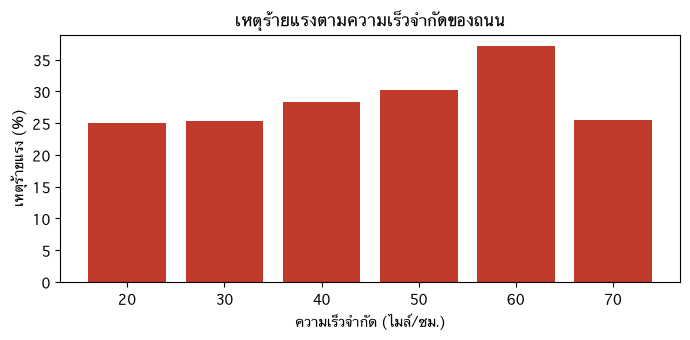

In [17]:
by_speed = clean.groupby("speed_limit")["severe"].agg(["size", "mean"])
by_speed.columns = ["จำนวนเหตุ", "สัดส่วนร้ายแรง"]
print(by_speed.round(3))

labels = []
for limit in by_speed.index:
    labels.append(str(int(limit)))

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(labels, by_speed["สัดส่วนร้ายแรง"] * 100, color="#c0392b")
ax.set(xlabel="ความเร็วจำกัด (ไมล์/ชม.)", ylabel="เหตุร้ายแรง (%)", title="เหตุร้ายแรงตามความเร็วจำกัดของถนน")
plt.tight_layout()
plt.show()

**อ่านกราฟ:** ถนน 20 และ 30 ไมล์ร้ายแรงประมาณ 25% แล้วเพิ่มตามความเร็วจำกัด จนถึง 37.1% ที่ถนน 60 ไมล์ แต่ถนน 70 ไมล์กลับลดลงเหลือ 25.5% ข้อ 4.2 จะดูว่าทำไม

### 4.2 ตัวเลขดิบหลอกตา: ทำไมถนน 70 ไมล์ร้ายแรงน้อยกว่า 60 ไมล์

In [18]:
check = pd.DataFrame({
    "speed_limit": clean["speed_limit"],
    "ถนนมีเกาะกลาง (%)": clean["road_type"].eq("3") * 100,
    "ชนหน้าเข้าหากัน (%)": clean["crash_type"].eq("ชนหน้าเข้าหากัน") * 100,
    "ชนท้าย (%)": clean["crash_type"].eq("ชนท้าย") * 100,
    "มีจักรยานยนต์ (%)": (clean["n_motorcycle"] > 0) * 100,
})
check.loc[check["speed_limit"].isin([60, 70])].groupby("speed_limit").mean().round(1)

,ถนนมีเกาะกลาง (%),ชนหน้าเข้าหากัน (%),ชนท้าย (%),มีจักรยานยนต์ (%)
speed_limit,,,,
60.0,5.1,19.3,18.5,16.3
70.0,85.5,4.9,50.7,7.7


**อ่านตาราง:** ถนน 70 ไมล์ 85.5% มีเกาะกลาง ส่วนถนน 60 ไมล์มีเพียง 5.1% เมื่อมีเกาะกลาง รถจึงไม่ค่อยชนหน้าเข้าหากัน (4.9% เทียบกับ 19.3%) แต่ชนท้ายมากกว่า (50.7% เทียบกับ 18.5%) ซึ่งเป็นการชนที่ร้ายแรงน้อยกว่า และมีจักรยานยนต์น้อยกว่าครึ่ง (7.7% เทียบกับ 16.3%)

ถนน 70 ไมล์จึงดูปลอดภัยเพราะแบบของถนนและแบบของการชน ไม่ใช่เพราะความเร็วสูงไม่อันตราย เป็น confounding แบบเดียวกับเรื่องเมาสุราในเล่มไทย หัวข้อ 10 จะแยกผลของความเร็วจำกัดออกจากปัจจัยอื่น

### 4.3 แสงสว่างและไฟถนน

In [19]:
light_names = {"1": "กลางวัน", "4": "มืด มีไฟถนนเปิด", "5": "มืด มีไฟถนนแต่ไม่เปิด",
               "6": "มืด ไม่มีไฟถนน", "7": "มืด ไม่ทราบเรื่องไฟ"}
light_group = clean["light_conditions"].map(light_names).fillna("ไม่ทราบ")

by_light = clean.groupby(light_group)["severe"].agg(["size", "mean"])
by_light.columns = ["จำนวนเหตุ", "สัดส่วนร้ายแรง"]
by_light.sort_values("สัดส่วนร้ายแรง", ascending=False).round(3)

,จำนวนเหตุ,สัดส่วนร้ายแรง
light_conditions,,
ไม่ทราบ,1,1.000
มืด ไม่มีไฟถนน,18812,0.369
มืด มีไฟถนนแต่ไม่เปิด,2504,0.312
มืด มีไฟถนนเปิด,60707,0.290
กลางวัน,222372,0.263
มืด ไม่ทราบเรื่องไฟ,4653,0.232


**อ่านตาราง:** ถนนมืดที่ไม่มีไฟถนนร้ายแรง 36.9% สูงกว่ากลางวัน (26.3%) และถนนมืดที่มีไฟเปิด (29.0%) ดูเหมือนไฟถนนช่วยลดความร้ายแรงได้มาก

แต่เหตุบนถนนมืดที่ไม่มีไฟ 84.8% อยู่นอกเมือง และ 70.2% อยู่บนถนนที่จำกัด 50 ไมล์ขึ้นไป ส่วนถนนมืดที่มีไฟเปิดมีเพียง 19.4% และ 10.6% ตัวเลขนี้จึงอาจเป็นผลของความเร็วมากกว่าไฟถนน ต้องดูผลในหัวข้อ 10 ที่คุมปัจจัยอื่นแล้ว

### 4.4 ขนาดของจักรยานยนต์
จักรยานยนต์ในไทยส่วนใหญ่ไม่เกิน 125cc ข้อมูลอังกฤษแยกขนาดได้ จึงดูว่าขนาดมีผลไหม

In [20]:
motorcycle_names = {"2": "ไม่เกิน 50cc", "3": "51–125cc", "4": "126–500cc", "5": "เกิน 500cc",
                    "23": "ไฟฟ้า", "97": "ไม่ทราบขนาด"}

bikes = vehicles.loc[vehicles["motorcycle"], ["collision_index", "vehicle_type"]]
bikes = bikes.merge(clean[["collision_index", "severe"]], on="collision_index")
bikes["ขนาด"] = bikes["vehicle_type"].map(motorcycle_names)

by_bike = bikes.groupby("ขนาด")["severe"].agg(["size", "mean"])
by_bike.columns = ["จำนวนจักรยานยนต์", "สัดส่วนเหตุร้ายแรง"]
by_bike.sort_values("สัดส่วนเหตุร้ายแรง", ascending=False).round(3)

,จำนวนจักรยานยนต์,สัดส่วนเหตุร้ายแรง
ขนาด,,
เกิน 500cc,14073,0.569
ไฟฟ้า,1183,0.497
126–500cc,4321,0.471
ไม่ทราบขนาด,2067,0.441
51–125cc,18584,0.344
ไม่เกิน 50cc,2419,0.306


**อ่านตาราง:** ยิ่งเครื่องใหญ่ยิ่งร้ายแรง จักรยานยนต์เกิน 500cc อยู่ในเหตุร้ายแรง 56.9% ขนาด 126–500cc อยู่ที่ 47.1% ส่วนขนาด 51–125cc อยู่ที่ 34.4% และไม่เกิน 50cc อยู่ที่ 30.6%

จักรยานยนต์ในไทยส่วนใหญ่อยู่ในกลุ่ม 51–125cc ถ้าจะเทียบกับไทย ควรดูตัวเลขของกลุ่มนี้มากกว่าตัวเลขรวม

## 5. สร้างปัจจัย
แปลงข้อมูลเป็นปัจจัยแบบ "มี" (1) หรือ "ไม่มี" (0) รวม 35 ตัว แบ่งเป็นสองชุด

**ชุด A: ปัจจัยแบบที่ข้อมูลไทยก็มี (20 ตัว)** ใช้เทียบกับเล่มไทย

| กลุ่ม | ปัจจัย |
|---|---|
| ใครอยู่ในเหตุ | มีคนเดินเท้า, มีจักรยาน, มีจักรยานยนต์, มีรถบรรทุกใหญ่, จักรยานยนต์กับรถบรรทุกใหญ่, มีรถบัส, รถ 2 คัน, รถ 3 คันขึ้นไป |
| ชนกันแบบไหน | ชนท้าย, ชนหน้าเข้าหากัน, ชนด้านข้าง, รถพลิกคว่ำ, รถออกนอกถนน, ชนต้นไม้หรือเสา, เลี้ยวขวา, แซง |
| เมื่อไรและที่ไหน | มืด, เสาร์อาทิตย์, ฝนตก, ทางแยก |

**ชุด B: ปัจจัยที่ข้อมูลไทยไม่มี (15 ตัว)**

| กลุ่ม | ปัจจัย |
|---|---|
| ถนน | จำกัดความเร็ว 20 / 40 / 50 / 60 / 70 ไมล์, นอกเมือง, ถนนมีเกาะกลาง, วงเวียน |
| สภาพแวดล้อม | มืดและไม่มีไฟถนน, ถนนเปียก, ถนนมีน้ำแข็งหรือหิมะ, หมอก |
| คนขับและรถ | จักรยานยนต์ใหญ่ (เกิน 500cc), คนขับอายุ 16–24, คนขับอายุ 70 ขึ้นไป |

**กรณีอ้างอิง** คือเหตุที่ปัจจัยทุกตัวเป็น 0 ได้แก่ รถยนต์คันเดียว บนถนนในเมืองที่จำกัด 30 ไมล์ ไม่มีเกาะกลาง ไม่ใช่ทางแยก ตอนกลางวันของวันธรรมดา อากาศดี ถนนแห้ง และคนขับอายุ 25–69 ปี

**ปัจจัยซ้อนกัน 2 คู่:**
- `มืดและไม่มีไฟถนน` เป็นส่วนหนึ่งของ `มืด` ค่าของมันคือผลที่เพิ่มขึ้นจากความมืดทั่วไป
- `จักรยานยนต์ใหญ่` เป็นส่วนหนึ่งของ `มีจักรยานยนต์` ค่าของมันคือผลที่เพิ่มขึ้นจากจักรยานยนต์ทั่วไป

**ไม่ใช้เป็นปัจจัย:** ความรุนแรงของผู้บาดเจ็บ จำนวนผู้บาดเจ็บ และการที่ตำรวจไปที่เกิดเหตุ เพราะเป็นคำตอบหรือเป็นผลของคำตอบ

In [21]:
factors = pd.DataFrame(index=clean.index)

# ---------- ชุด A ----------
# ใครอยู่ในเหตุ
factors["มีคนเดินเท้า"] = clean["n_pedestrian"] > 0
factors["มีจักรยาน"] = clean["n_bicycle"] > 0
factors["มีจักรยานยนต์"] = clean["n_motorcycle"] > 0
factors["มีรถบรรทุกใหญ่"] = clean["n_heavy_goods"] > 0
factors["จักรยานยนต์กับรถบรรทุกใหญ่"] = factors["มีจักรยานยนต์"] & factors["มีรถบรรทุกใหญ่"]
factors["มีรถบัส"] = clean["n_bus"] > 0
factors["รถ 2 คัน"] = clean["number_of_vehicles"].eq(2)
factors["รถ 3 คันขึ้นไป"] = clean["number_of_vehicles"] >= 3

# ชนกันแบบไหน
factors["ชนท้าย"] = clean["crash_type"].eq("ชนท้าย")
factors["ชนหน้าเข้าหากัน"] = clean["crash_type"].eq("ชนหน้าเข้าหากัน")
factors["ชนด้านข้าง"] = clean["crash_type"].eq("ชนด้านข้าง")
factors["รถพลิกคว่ำ"] = clean["n_overturned"] > 0
factors["รถออกนอกถนน"] = clean["n_left_road"] > 0
factors["ชนต้นไม้หรือเสา"] = clean["n_hit_tree_or_pole"] > 0
factors["เลี้ยวขวา"] = clean["n_turning_right"] > 0
factors["แซง"] = clean["n_overtaking"] > 0

# เมื่อไรและที่ไหน
factors["มืด"] = clean["light_conditions"].isin(["4", "5", "6", "7"])
factors["เสาร์อาทิตย์"] = clean["day_of_week"].isin(["1", "7"])
factors["ฝนตก"] = clean["weather_conditions"].isin(["2", "5"])
# ทางแยกตามรหัสชุดใหม่: 13 = สามแยก, 16 = สี่แยก, 17 = แยกเกิน 4 ทาง, 18 = ทางเข้าบ้าน, 19 = ทางแยกอื่น
factors["ทางแยก"] = clean["junction_detail"].isin(["13", "16", "17", "18", "19"])

# ---------- ชุด B ----------
# ถนน (กรณีอ้างอิงคือ 30 ไมล์)
for limit in [20, 40, 50, 60, 70]:
    factors[f"จำกัดความเร็ว {limit} ไมล์"] = clean["speed_limit"].eq(limit)
factors["นอกเมือง"] = clean["urban_or_rural_area"].eq("2")
factors["ถนนมีเกาะกลาง"] = clean["road_type"].eq("3")
factors["วงเวียน"] = clean["road_type"].eq("1")

# สภาพแวดล้อม
factors["มืดและไม่มีไฟถนน"] = clean["light_conditions"].isin(["5", "6"])
factors["ถนนเปียก"] = clean["road_surface_conditions"].eq("2")
factors["ถนนมีน้ำแข็งหรือหิมะ"] = clean["road_surface_conditions"].isin(["3", "4"])
factors["หมอก"] = clean["weather_conditions"].eq("7")

# คนขับและรถ
factors["จักรยานยนต์ใหญ่ (เกิน 500cc)"] = clean["n_big_motorcycle"] > 0
factors["คนขับอายุ 16–24"] = clean["n_young_driver"] > 0
factors["คนขับอายุ 70 ขึ้นไป"] = clean["n_old_driver"] > 0

factors = factors.astype(int)
factor_names = list(factors.columns)

# ชุด A คือ 20 ปัจจัยแรกตามลำดับที่สร้าง
thai_like_factors = factor_names[:20]
uk_only_factors = factor_names[20:]
print("ปัจจัยทั้งหมด:", len(factor_names), "| ชุด A:", len(thai_like_factors), "| ชุด B:", len(uk_only_factors))

ปัจจัยทั้งหมด: 35 | ชุด A: 20 | ชุด B: 15


### 5.1 เหตุร้ายแรงกับเหตุไม่ร้ายแรง มีปัจจัยต่างกันตรงไหน

In [22]:
severe_rows = factors.loc[clean["severe"].eq(1)]
other_rows = factors.loc[clean["severe"].eq(0)]

profile = pd.DataFrame({
    "พบในเหตุร้ายแรง (%)": severe_rows.mean() * 100,
    "พบในเหตุไม่ร้ายแรง (%)": other_rows.mean() * 100,
})
profile["ต่างกัน (เท่า)"] = profile["พบในเหตุร้ายแรง (%)"] / profile["พบในเหตุไม่ร้ายแรง (%)"]
profile = profile.sort_values("ต่างกัน (เท่า)", ascending=False)
profile.round(2)

,พบในเหตุร้ายแรง (%),พบในเหตุไม่ร้ายแรง (%),ต่างกัน (เท่า)
จักรยานยนต์ใหญ่ (เกิน 500cc),9.07,2.65,3.42
จักรยานยนต์กับรถบรรทุกใหญ่,0.54,0.17,3.18
มีจักรยานยนต์,21.30,10.47,2.03
ชนต้นไม้หรือเสา,4.39,2.57,1.71
จำกัดความเร็ว 60 ไมล์,18.49,11.87,1.56
รถพลิกคว่ำ,12.13,7.81,1.55
รถออกนอกถนน,25.13,16.71,1.50
มืดและไม่มีไฟถนน,9.10,6.07,1.50
มีคนเดินเท้า,22.54,16.45,1.37
ชนหน้าเข้าหากัน,17.27,12.81,1.35


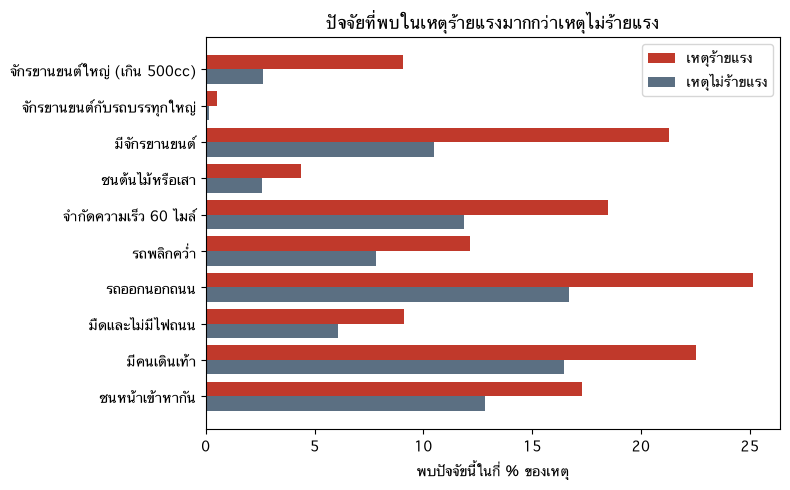

In [23]:
# วาดเฉพาะ 10 ปัจจัยที่ต่างกันมากที่สุด
top_profile = profile.head(10).iloc[::-1]
positions = np.arange(len(top_profile))

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(positions + 0.2, top_profile["พบในเหตุร้ายแรง (%)"], height=0.4, color="#c0392b", label="เหตุร้ายแรง")
ax.barh(positions - 0.2, top_profile["พบในเหตุไม่ร้ายแรง (%)"], height=0.4, color="#5b6f82", label="เหตุไม่ร้ายแรง")
ax.set_yticks(positions)
ax.set_yticklabels(top_profile.index)
ax.set(xlabel="พบปัจจัยนี้ในกี่ % ของเหตุ", title="ปัจจัยที่พบในเหตุร้ายแรงมากกว่าเหตุไม่ร้ายแรง")
ax.legend()
plt.tight_layout()
plt.show()

**อ่านกราฟ:** จักรยานยนต์เกิน 500cc ต่างกันมากที่สุดเมื่อนับเป็นจำนวนเท่า คือพบในเหตุร้ายแรง 9.1% แต่พบในเหตุไม่ร้ายแรง 2.7% (3.4 เท่า) จักรยานยนต์ทุกขนาดพบ 21.3% กับ 10.5% และถนน 60 ไมล์พบ 18.5% กับ 11.9%

ความต่างเล็กกว่าข้อมูลไทยมาก ในไทยจักรยานยนต์พบ 53.1% กับ 14.2% และคนเดินเท้าต่างกันถึง 12.8 เท่า แต่ในอังกฤษคนเดินเท้าพบ 22.5% กับ 16.5% เท่านั้น สาเหตุหลักคือข้อมูลอังกฤษไม่มีเหตุที่ไม่มีใครบาดเจ็บ เหตุ "ไม่ร้ายแรง" ของอังกฤษจึงยังมีคนบาดเจ็บ และมีคนเดินเท้าหรือจักรยานยนต์ปนอยู่มาก

### 5.2 บันทึกตารางปัจจัย
เพิ่มเขตตำรวจ (`police_force`) เข้าไปด้วย ไม่ได้เป็นปัจจัยที่จะรายงาน แต่ใส่ให้โมเดลเพื่อ **คุมความต่างของพื้นที่** เหมือนจังหวัดในเล่มไทย

In [24]:
place_columns = ["police_force"]
model_columns = factor_names + place_columns

features = factors.copy()
features["police_force"] = clean["police_force"]
features["year"] = clean["year"]
features["severe"] = clean["severe"]
print(features.shape)

(309049, 38)


## 6. แบ่งข้อมูล
แบ่งตามเวลา เหมือนเล่มไทย
- **Train:** ปี 2021–2023 ใช้ฝึกโมเดล
- **Validation:** ปี 2024 ใช้เลือกโมเดล
- **Test:** ปี 2025 ใช้ประเมินครั้งสุดท้าย โมเดลไม่เคยเห็นข้อมูลชุดนี้

In [25]:
def find_split(year):
    if year <= 2023:
        return "train"
    if year == 2024:
        return "validation"
    return "test"


features["split"] = features["year"].apply(find_split)

feature_path = feature_dir / "collisions_factors.csv"
features.to_csv(feature_path, index=False, encoding="utf-8-sig")
print("บันทึกแล้ว:", feature_path.relative_to(project_dir))

train = features.loc[features["split"].eq("train")]
validation = features.loc[features["split"].eq("validation")]
test = features.loc[features["split"].eq("test")]

for name, part in [("Train", train), ("Validation", validation), ("Test", test)]:
    print(name, "| จำนวนเหตุ:", len(part), "| ร้ายแรง:", round(part["severe"].mean() * 100, 1), "%")

บันทึกแล้ว: data/explore_idea/uk_severity_factors/features/collisions_factors.csv
Train | จำนวนเหตุ: 161904 | ร้ายแรง: 27.3 %
Validation | จำนวนเหตุ: 59297 | ร้ายแรง: 28.5 %
Test | จำนวนเหตุ: 87848 | ร้ายแรง: 27.0 %


## 7. วิธีวัดผล
ใช้ชุดเดียวกับเล่มไทย

**ชั้นที่ 1: โมเดลเข้ากับความจริงแค่ไหน**
- **PR-AUC** (ตัวหลัก): เมื่อโมเดลชี้ว่าร้ายแรง ชี้ถูกแค่ไหน ค่าของการเดาสุ่มเท่ากับสัดส่วนเหตุร้ายแรง
- **PR-AUC ÷ เดาสุ่ม:** PR-AUC เป็นกี่เท่าของการเดาสุ่ม ใช้เทียบข้อมูลไทยกับอังกฤษ เพราะสองชุดมีสัดส่วนเหตุร้ายแรงไม่เท่ากัน
- **ROC-AUC:** เรียงลำดับเหตุร้ายแรงไว้เหนือเหตุไม่ร้ายแรงได้ถูกแค่ไหน ค่า 0.5 คือเดาสุ่ม
- **Brier score:** เปอร์เซ็นต์ที่ทำนายคลาดเคลื่อนเท่าไร ยิ่งต่ำยิ่งดี

**ชั้นที่ 2: ตัวเลขของแต่ละปัจจัยเชื่อได้ไหม** (หัวข้อ 10) ดูว่าคงที่ข้ามช่วงปีไหม และแกว่งแค่ไหนเมื่อสุ่มข้อมูลซ้ำ

**Baseline:** ใช้สัดส่วนเหตุร้ายแรงของ "มีจักรยานยนต์" กับ "ไม่มีจักรยานยนต์" จากข้อมูล Train เหมือนเล่มไทย

In [26]:
def evaluate(name, y_true, y_prob):
    pr_auc = average_precision_score(y_true, y_prob)
    return {
        "วิธี": name,
        "PR-AUC": pr_auc,
        "PR-AUC ÷ เดาสุ่ม": pr_auc / y_true.mean(),
        "ROC-AUC": roc_auc_score(y_true, y_prob),
        "Brier": brier_score_loss(y_true, y_prob),
    }


def baseline_predict(train_part, target_part):
    # สัดส่วนร้ายแรงของกลุ่มที่มีและไม่มีจักรยานยนต์ จากข้อมูลฝึก
    rate_by_group = train_part.groupby("มีจักรยานยนต์")["severe"].mean()
    return target_part["มีจักรยานยนต์"].map(rate_by_group).values


validation_baseline = baseline_predict(train, validation)
pd.DataFrame([evaluate("Baseline", validation["severe"], validation_baseline)]).round(3)

,วิธี,PR-AUC,PR-AUC ÷ เดาสุ่ม,ROC-AUC,Brier
0,Baseline,0.319,1.122,0.554,0.199


## 8. เลือกโมเดล
ลอง 4 โมเดลกับปัจจัยชุดเดียวกัน แล้ววัดผลบน Validation (ปี 2024) ปัจจัย 35 ตัวส่งเข้าโมเดลตรง ๆ เพราะเป็น 0/1 อยู่แล้ว ส่วนเขตตำรวจแปลงด้วย `OneHotEncoder`

In [27]:
def make_prepare(factor_list):
    place_step = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    return ColumnTransformer([
        ("factor", "passthrough", factor_list),
        ("place", place_step, place_columns),
    ])


estimators = {
    "Logistic Regression": LogisticRegression(max_iter=2000),
    "Decision Tree": DecisionTreeClassifier(max_depth=6, min_samples_leaf=50, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, min_samples_leaf=20, n_jobs=-1, random_state=42),
    "Gradient Boosting": HistGradientBoostingClassifier(random_state=42),
}


def build_model(name, factor_list=None):
    if factor_list is None:
        factor_list = factor_names
    return make_pipeline(make_prepare(factor_list), clone(estimators[name]))

In [28]:
validation_results = [evaluate("Baseline", validation["severe"], validation_baseline)]

for name in estimators:
    model = build_model(name)
    model.fit(train[model_columns], train["severe"])
    probability = model.predict_proba(validation[model_columns])[:, 1]
    validation_results.append(evaluate(name, validation["severe"], probability))

pd.DataFrame(validation_results).round(3)

,วิธี,PR-AUC,PR-AUC ÷ เดาสุ่ม,ROC-AUC,Brier
0,Baseline,0.319,1.122,0.554,0.199
1,Logistic Regression,0.461,1.619,0.681,0.186
2,Decision Tree,0.434,1.524,0.660,0.189
3,Random Forest,0.476,1.673,0.689,0.184
4,Gradient Boosting,0.482,1.692,0.691,0.183


**อ่านตาราง:** ทุกโมเดลชนะ Baseline (0.319) Gradient Boosting ได้ PR-AUC สูงสุด (0.482) ตามด้วย Random Forest (0.476) Logistic Regression (0.461) และ Decision Tree (0.434)

**เลือก Logistic Regression** ด้วยเหตุผลเดียวกับเล่มไทย คือโจทย์ถามว่า "ร้ายแรงเพราะปัจจัยอะไร" และ Logistic Regression ให้ตัวเลขหนึ่งตัวต่อหนึ่งปัจจัย ส่วนที่เสียไปเทียบกับ Gradient Boosting คือ PR-AUC 0.021 น้อยกว่าเล่มไทยที่เสีย 0.060

## 9. ประเมินบน Test
ฝึกโมเดลใหม่ด้วยปี 2021–2024 แล้ววัดผลกับปี 2025 ที่โมเดลไม่เคยเห็น

In [29]:
train_validation = pd.concat([train, validation])
test_x = test[model_columns]
test_y = test["severe"]

test_model = build_model("Logistic Regression")
test_model.fit(train_validation[model_columns], train_validation["severe"])
test_prob = test_model.predict_proba(test_x)[:, 1]

boosting_model = build_model("Gradient Boosting")
boosting_model.fit(train_validation[model_columns], train_validation["severe"])
boosting_prob = boosting_model.predict_proba(test_x)[:, 1]

same_for_all = np.full(len(test), train_validation["severe"].mean())
test_baseline = baseline_predict(train_validation, test)

test_results = [
    evaluate("ให้ทุกเหตุได้ค่าเฉลี่ยเท่ากัน", test_y, same_for_all),
    evaluate("Baseline (มีจักรยานยนต์ไหม)", test_y, test_baseline),
    evaluate("Logistic Regression (ตัวที่เลือก)", test_y, test_prob),
    evaluate("Gradient Boosting (ไว้เทียบ)", test_y, boosting_prob),
]
pd.DataFrame(test_results).round(3)

,วิธี,PR-AUC,PR-AUC ÷ เดาสุ่ม,ROC-AUC,Brier
0,ให้ทุกเหตุได้ค่าเฉลี่ยเท่ากัน,0.270,1.000,0.500,0.197
1,Baseline (มีจักรยานยนต์ไหม),0.297,1.100,0.548,0.195
2,Logistic Regression (ตัวที่เลือก),0.434,1.606,0.675,0.182
3,Gradient Boosting (ไว้เทียบ),0.455,1.687,0.687,0.179


**อ่านตาราง:**
- **ชนะวิธีง่าย ๆ:** Logistic Regression ได้ PR-AUC 0.434 สูงกว่าการให้ค่าเฉลี่ยเท่ากันทุกเหตุ (0.270) และ Baseline (0.297)
- **แต่แยกเหตุได้ไม่ดีนัก:** PR-AUC เป็น 1.6 เท่าของการเดาสุ่ม ขณะที่เล่มไทยได้ 3.2 เท่า และ ROC-AUC 0.675 ต่ำกว่าเล่มไทย (0.818) หัวข้อ 9.4 จะดูว่าเทียบกันแบบนี้ยุติธรรมไหม
- **ไม่ได้จำข้อมูลปีเก่า:** เมื่อหารด้วยค่าเดาสุ่มแล้ว Test ได้ 1.61 เท่ากับ Validation
- **ราคาของการอ่านออก:** Gradient Boosting ได้ 0.455 สูงกว่า 0.021

### 9.1 เปอร์เซ็นต์ที่โมเดลบอก ตรงกับความจริงไหม (Calibration)

   โมเดลทำนาย (%)  ร้ายแรงจริง (%)
0             9.5              8.7
1            13.8             13.8
2            17.7             18.6
3            21.3             21.3
4            24.8             25.1
5            28.0             26.7
6            31.6             29.8
7            36.0             33.8
8            42.4             39.8
9            57.4             52.4


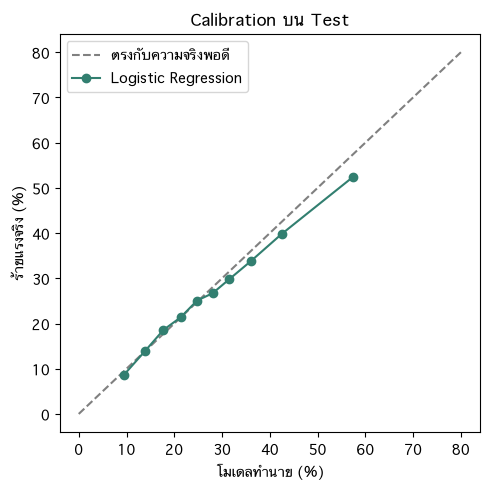

In [30]:
actual_rate, predicted_rate = calibration_curve(test_y, test_prob, n_bins=10, strategy="quantile")

calibration_table = pd.DataFrame({
    "โมเดลทำนาย (%)": predicted_rate * 100,
    "ร้ายแรงจริง (%)": actual_rate * 100,
})
print(calibration_table.round(1))

fig, ax = plt.subplots(figsize=(5, 5))
ax.plot([0, 80], [0, 80], linestyle="--", color="gray", label="ตรงกับความจริงพอดี")
ax.plot(predicted_rate * 100, actual_rate * 100, marker="o", color="#327f70", label="Logistic Regression")
ax.set(xlabel="โมเดลทำนาย (%)", ylabel="ร้ายแรงจริง (%)", title="Calibration บน Test")
ax.legend()
plt.tight_layout()
plt.show()

**อ่านกราฟ:** กลุ่มที่โมเดลให้ค่าต่ำถึงกลาง (9.5% ถึง 24.8%) ตรงกับความจริงภายใน 1 จุด กลุ่มที่โมเดลให้ค่าสูงทำนายเกินจริง 2–5 จุด เช่น ทำนาย 57.4% ร้ายแรงจริง 52.4% เปอร์เซ็นต์ที่โมเดลบอกจึงใช้อ่านได้ แต่ควรระวังในกลุ่มเสี่ยงสูง

### 9.2 ถ้าใช้ตัดสินว่า "ร้ายแรง" หรือ "ไม่ร้ายแรง"
ใช้เกณฑ์ 30% เท่ากับเล่มไทย

In [31]:
threshold = 0.30
predicted_severe = (test_prob >= threshold).astype(int)
matrix = confusion_matrix(test_y, predicted_severe)

true_negative = matrix[0, 0]
false_positive = matrix[0, 1]
false_negative = matrix[1, 0]
true_positive = matrix[1, 1]

print("เหตุร้ายแรงจริง:", true_positive + false_negative, "| โมเดลจับได้:", true_positive, "| พลาด:", false_negative)
print("โมเดลบอกว่าร้ายแรง:", true_positive + false_positive, "| ถูก:", true_positive, "| ผิด:", false_positive)
print()
print("Recall (จับเหตุร้ายแรงได้):", round(true_positive / (true_positive + false_negative) * 100, 1), "%")
print("Precision (บอกว่าร้ายแรงแล้วถูก):", round(true_positive / (true_positive + false_positive) * 100, 1), "%")

เหตุร้ายแรงจริง: 23720 | โมเดลจับได้: 13484 | พลาด: 10236
โมเดลบอกว่าร้ายแรง: 34417 | ถูก: 13484 | ผิด: 20933

Recall (จับเหตุร้ายแรงได้): 56.8 %
Precision (บอกว่าร้ายแรงแล้วถูก): 39.2 %


**อ่านผล:** เหตุร้ายแรงจริง 23,720 เหตุ โมเดลจับได้ 13,484 เหตุ (56.8%) ใกล้กับเล่มไทย (57.1%) แต่เมื่อโมเดลบอกว่าร้ายแรง จะถูกเพียง 39.2% ขณะที่เล่มไทยถูก 52.5% โมเดลนี้จึงใช้ตัดสินรายเหตุไม่ได้เช่นกัน

### 9.3 ปัจจัยที่ข้อมูลไทยไม่มี ช่วยได้แค่ไหน
ฝึก Logistic Regression สองตัวด้วยข้อมูลเดียวกัน ต่างกันแค่ชุดปัจจัย
- **ชุด A อย่างเดียว:** ปัจจัยแบบที่ข้อมูลไทยก็มี
- **ชุด A + B:** เพิ่มความเร็วจำกัด ไฟถนน ผิวถนน อายุคนขับ และอื่น ๆ

In [32]:
ablation_results = []
for name, factor_list in [("ชุด A อย่างเดียว (แบบข้อมูลไทย)", thai_like_factors),
                          ("ชุด A + B (เพิ่มข้อมูลที่ไทยไม่มี)", factor_names)]:
    columns = factor_list + place_columns
    model = build_model("Logistic Regression", factor_list)
    model.fit(train_validation[columns], train_validation["severe"])
    probability = model.predict_proba(test[columns])[:, 1]
    ablation_results.append(evaluate(name, test_y, probability))

pd.DataFrame(ablation_results).round(3)

,วิธี,PR-AUC,PR-AUC ÷ เดาสุ่ม,ROC-AUC,Brier
0,ชุด A อย่างเดียว (แบบข้อมูลไทย),0.404,1.496,0.657,0.186
1,ชุด A + B (เพิ่มข้อมูลที่ไทยไม่มี),0.434,1.606,0.675,0.182


**อ่านตาราง:** เมื่อเพิ่มปัจจัยชุด B แล้ว PR-AUC เพิ่มจาก 0.404 เป็น 0.434 และ ROC-AUC เพิ่มจาก 0.657 เป็น 0.675

ข้อมูลที่ไทยไม่มีช่วยจริง แต่ช่วยไม่มาก คือจาก 1.50 เป็น 1.61 เท่าของการเดาสุ่ม ความเร็วจำกัด ไฟถนน ผิวถนน และอายุคนขับ จึงยังไม่ใช่ข้อมูลที่ขาดหายไปมากที่สุด

### 9.4 เทียบกับข้อมูลไทยแบบยุติธรรม
ข้อมูลไทย 44% เป็นเหตุที่ไม่มีใครบาดเจ็บ ซึ่งแยกออกจากเหตุร้ายแรงได้ง่าย แต่ข้อมูลอังกฤษมีแต่เหตุที่มีคนบาดเจ็บ โจทย์ของอังกฤษคือแยก "บาดเจ็บสาหัสหรือเสียชีวิต" ออกจาก "บาดเจ็บเล็กน้อย" ซึ่งยากกว่า

ถ้าเทียบคะแนนตรง ๆ จะไม่ยุติธรรม จึงฝึกโมเดลไทยใหม่ด้วยวิธีเดียวกับเล่ม `severity_factors` แต่ใช้เฉพาะเหตุไทยที่มีผู้บาดเจ็บ แล้วเทียบกับอังกฤษ

เซลล์นี้อ่านไฟล์ที่ notebook `severity_factors` สร้างไว้ ถ้ายังไม่มี ให้รันเล่มนั้นก่อน

In [33]:
thai_dir = project_dir / "data" / "explore_idea" / "severity_factors"
thai_clean = pd.read_csv(thai_dir / "clean" / "accidents_clean.csv", encoding="utf-8-sig")
thai_features = pd.read_csv(thai_dir / "features" / "accidents_factors.csv", encoding="utf-8-sig")

# สองไฟล์เรียงแถวตรงกัน (หนึ่งแถวคือเหตุเดียวกัน)
thai_injured = (thai_clean["deaths"] + thai_clean["serious_injuries"] + thai_clean["minor_injuries"]) > 0
print("เหตุไทยที่มีผู้บาดเจ็บ:", int(thai_injured.sum()), "จาก", len(thai_clean), "เหตุ")

thai_place_columns = ["province", "road_type"]
thai_factor_names = []
for column in thai_features.columns:
    if column not in thai_place_columns + ["year", "severe", "split"]:
        thai_factor_names.append(column)


def thai_test_score(name, rows):
    # ฝึกด้วยปี 2020–2024 วัดผลกับปี 2025–2026 เหมือนเล่มไทย
    prepare = ColumnTransformer([
        ("factor", "passthrough", thai_factor_names),
        ("place", OneHotEncoder(handle_unknown="ignore", sparse_output=False), thai_place_columns),
    ])
    model = make_pipeline(prepare, LogisticRegression(max_iter=2000))
    train_part = rows.loc[rows["split"].ne("test")]
    test_part = rows.loc[rows["split"].eq("test")]
    model.fit(train_part[thai_factor_names + thai_place_columns], train_part["severe"])
    probability = model.predict_proba(test_part[thai_factor_names + thai_place_columns])[:, 1]
    return evaluate(name, test_part["severe"], probability)


compare_results = [
    thai_test_score("ไทย: ทุกเหตุ (แบบในเล่มไทย)", thai_features),
    thai_test_score("ไทย: เฉพาะเหตุที่มีผู้บาดเจ็บ", thai_features.loc[thai_injured]),
    ablation_results[0],
    ablation_results[1],
]
compare_table = pd.DataFrame(compare_results)
compare_table["วิธี"] = ["ไทย: ทุกเหตุ (แบบในเล่มไทย)", "ไทย: เฉพาะเหตุที่มีผู้บาดเจ็บ",
                         "อังกฤษ: ชุด A (แบบข้อมูลไทย)", "อังกฤษ: ชุด A + B"]
compare_table.round(3)

เหตุไทยที่มีผู้บาดเจ็บ: 83523 จาก 150097 เหตุ


,วิธี,PR-AUC,PR-AUC ÷ เดาสุ่ม,ROC-AUC,Brier
0,ไทย: ทุกเหตุ (แบบในเล่มไทย),0.533,3.161,0.818,0.105
1,ไทย: เฉพาะเหตุที่มีผู้บาดเจ็บ,0.595,1.926,0.752,0.175
2,อังกฤษ: ชุด A (แบบข้อมูลไทย),0.404,1.496,0.657,0.186
3,อังกฤษ: ชุด A + B,0.434,1.606,0.675,0.182


**อ่านตาราง:** นี่คือคำตอบของคำถามที่ 2
- **ข้อมูลไทยไม่ได้แย่กว่า:** เมื่อใช้เฉพาะเหตุที่มีผู้บาดเจ็บ ข้อมูลไทยได้ ROC-AUC 0.752 และ PR-AUC 1.93 เท่าของการเดาสุ่ม ดีกว่าข้อมูลอังกฤษทั้งสองชุด (ROC-AUC 0.657 และ 0.675)
- **คะแนนของเล่มไทยสูงส่วนหนึ่งเพราะโจทย์ง่ายกว่า:** พอตัดเหตุที่ไม่มีใครบาดเจ็บออก ROC-AUC ลดจาก 0.818 เหลือ 0.752
- **โจทย์นี้ยากโดยธรรมชาติ:** ทั้งที่อังกฤษมีปัจจัยมากกว่า โมเดลก็ยังแยก "บาดเจ็บสาหัสหรือเสียชีวิต" ออกจาก "บาดเจ็บเล็กน้อย" ได้ปานกลาง สิ่งที่ตัดสินจริงน่าจะเป็นข้อมูลที่ไม่มีในข้อมูลตำรวจของทั้งสองประเทศ เช่น ความเร็วตอนชน การสวมหมวกหรือคาดเข็มขัด และอายุหรือร่างกายของผู้บาดเจ็บ

📌 คะแนนทำนายรายเหตุที่ไม่สูงไม่ได้แปลว่าข้อมูลใช้ไม่ได้ ถ้าโจทย์คือ "ระบุปัจจัย" สิ่งที่ต้องวัดคือ odds ratio ของแต่ละปัจจัยคงที่และแม่นไหม ซึ่งเป็นเรื่องของหัวข้อ 10

## 10. คำตอบส่วนที่ 1: ปัจจัยไหนทำให้เหตุร้ายแรง
ฝึก Logistic Regression ด้วยข้อมูลทุกปี แล้วอ่าน **odds ratio** ของแต่ละปัจจัย

📌 **Odds ratio** คือ odds ของเหตุร้ายแรงเพิ่มกี่เท่าเมื่อมีปัจจัยนี้ โดยที่ปัจจัยอื่นและเขตตำรวจเหมือนเดิม มากกว่า 1 คือทำให้ร้ายแรงขึ้น น้อยกว่า 1 คือมากับเหตุที่ร้ายแรงน้อยลง

ตัวอย่าง: โอกาสร้ายแรง 20% คือ odds 0.25 (20 ต่อ 80) ถ้า odds ratio เป็น 3 จะได้ odds 0.75 ซึ่งคือโอกาสประมาณ 43%

In [34]:
def get_odds_ratios(model):
    # ค่าสัมประสิทธิ์ของปัจจัยอยู่ลำดับแรก ตามลำดับใน make_prepare
    coefficients = model[-1].coef_[0]
    factor_coefficients = coefficients[:len(factor_names)]
    return pd.Series(np.exp(factor_coefficients), index=factor_names)


all_x = features[model_columns]
all_y = features["severe"]

final_model = build_model("Logistic Regression")
final_model.fit(all_x, all_y)

factor_table = pd.DataFrame({
    "ชุด": "A",
    "พบในเหตุ (%)": factors.mean() * 100,
    "odds ratio": get_odds_ratios(final_model),
})
factor_table.loc[uk_only_factors, "ชุด"] = "B"
factor_table.sort_values("odds ratio", ascending=False).round(2)

,ชุด,พบในเหตุ (%),odds ratio
มีจักรยานยนต์,A,13.44,2.83
มีจักรยาน,A,13.42,2.33
มีคนเดินเท้า,A,18.12,2.17
ชนหน้าเข้าหากัน,A,14.04,1.82
จักรยานยนต์ใหญ่ (เกิน 500cc),B,4.42,1.79
รถออกนอกถนน,A,19.02,1.52
จำกัดความเร็ว 60 ไมล์,B,13.68,1.47
คนขับอายุ 70 ขึ้นไป,B,10.49,1.43
มีรถบัส,A,2.66,1.43
จำกัดความเร็ว 50 ไมล์,B,4.57,1.36


### 10.1 ปัจจัยคงที่ข้ามช่วงปีไหม
ฝึกโมเดลแยกสองช่วง คือปี 2021–2023 และปี 2024–2025 ถ้าปัจจัยมีผลจริง สองช่วงควรได้ค่าใกล้กัน

In [35]:
early_rows = features["year"] <= 2023
late_rows = features["year"] >= 2024

early_model = build_model("Logistic Regression")
early_model.fit(all_x.loc[early_rows], all_y.loc[early_rows])

late_model = build_model("Logistic Regression")
late_model.fit(all_x.loc[late_rows], all_y.loc[late_rows])

factor_table["ปี 2021–2023"] = get_odds_ratios(early_model)
factor_table["ปี 2024–2025"] = get_odds_ratios(late_model)

### 10.2 ช่วงความไม่แน่นอน
📌 ใช้วิธี **bootstrap** คือสุ่มหยิบเหตุจากข้อมูลเดิมแบบใส่คืน ให้ได้จำนวนเท่าเดิม แล้วฝึกโมเดลใหม่ ทำซ้ำหลายรอบ ช่วงที่ครอบ 95% ของค่าที่ได้บอกว่า odds ratio แกว่งได้แค่ไหน

ทำ 100 รอบเท่าเล่มไทย เซลล์นี้ใช้เวลาประมาณ 1 นาที

In [36]:
bootstrap_round_count = 100
random_generator = np.random.default_rng(42)
row_count = len(all_x)

bootstrap_rounds = []
for round_number in range(bootstrap_round_count):
    picked_rows = random_generator.integers(0, row_count, row_count)
    sample_x = all_x.iloc[picked_rows]
    sample_y = all_y.iloc[picked_rows]

    sample_model = build_model("Logistic Regression")
    sample_model.fit(sample_x, sample_y)
    bootstrap_rounds.append(get_odds_ratios(sample_model))

bootstrap_table = pd.DataFrame(bootstrap_rounds)
factor_table["ต่ำสุด"] = bootstrap_table.quantile(0.025)
factor_table["สูงสุด"] = bootstrap_table.quantile(0.975)

### 10.3 สรุปผลของแต่ละปัจจัย
ตัดสินจาก 2 เงื่อนไขพร้อมกัน เหมือนเล่มไทย
- **เพิ่ม:** ช่วงความไม่แน่นอนอยู่เหนือ 1 ทั้งช่วง และมากกว่า 1 ทั้งสองช่วงปี
- **ลด:** ช่วงความไม่แน่นอนอยู่ใต้ 1 ทั้งช่วง และน้อยกว่า 1 ทั้งสองช่วงปี
- **ไม่ชัด:** กรณีอื่น

In [37]:
def judge(row):
    if row["ต่ำสุด"] > 1 and row["ปี 2021–2023"] > 1 and row["ปี 2024–2025"] > 1:
        return "เพิ่ม"
    if row["สูงสุด"] < 1 and row["ปี 2021–2023"] < 1 and row["ปี 2024–2025"] < 1:
        return "ลด"
    return "ไม่ชัด"


factor_table["ผล"] = factor_table.apply(judge, axis=1)
factor_table = factor_table.sort_values("odds ratio", ascending=False)

table_path = result_dir / "factor_table.csv"
factor_table.to_csv(table_path, encoding="utf-8-sig", index_label="ปัจจัย")
print("บันทึกแล้ว:", table_path.relative_to(project_dir))
print(factor_table["ผล"].value_counts())
factor_table.round(2)

บันทึกแล้ว: data/explore_idea/uk_severity_factors/results/factor_table.csv
ผล
เพิ่ม     23
ลด         8
ไม่ชัด     4
Name: count, dtype: int64


,ชุด,พบในเหตุ (%),odds ratio,ปี 2021–2023,ปี 2024–2025,ต่ำสุด,สูงสุด,ผล
มีจักรยานยนต์,A,13.44,2.83,3.18,2.51,2.74,2.91,เพิ่ม
มีจักรยาน,A,13.42,2.33,2.42,2.25,2.28,2.40,เพิ่ม
มีคนเดินเท้า,A,18.12,2.17,2.30,2.05,2.11,2.25,เพิ่ม
ชนหน้าเข้าหากัน,A,14.04,1.82,1.67,1.98,1.77,1.95,เพิ่ม
จักรยานยนต์ใหญ่ (เกิน 500cc),B,4.42,1.79,1.72,1.87,1.71,1.87,เพิ่ม
รถออกนอกถนน,A,19.02,1.52,1.57,1.47,1.47,1.56,เพิ่ม
จำกัดความเร็ว 60 ไมล์,B,13.68,1.47,1.49,1.46,1.42,1.52,เพิ่ม
คนขับอายุ 70 ขึ้นไป,B,10.49,1.43,1.48,1.39,1.40,1.48,เพิ่ม
มีรถบัส,A,2.66,1.43,1.46,1.38,1.35,1.49,เพิ่ม
จำกัดความเร็ว 50 ไมล์,B,4.57,1.36,1.40,1.31,1.30,1.43,เพิ่ม


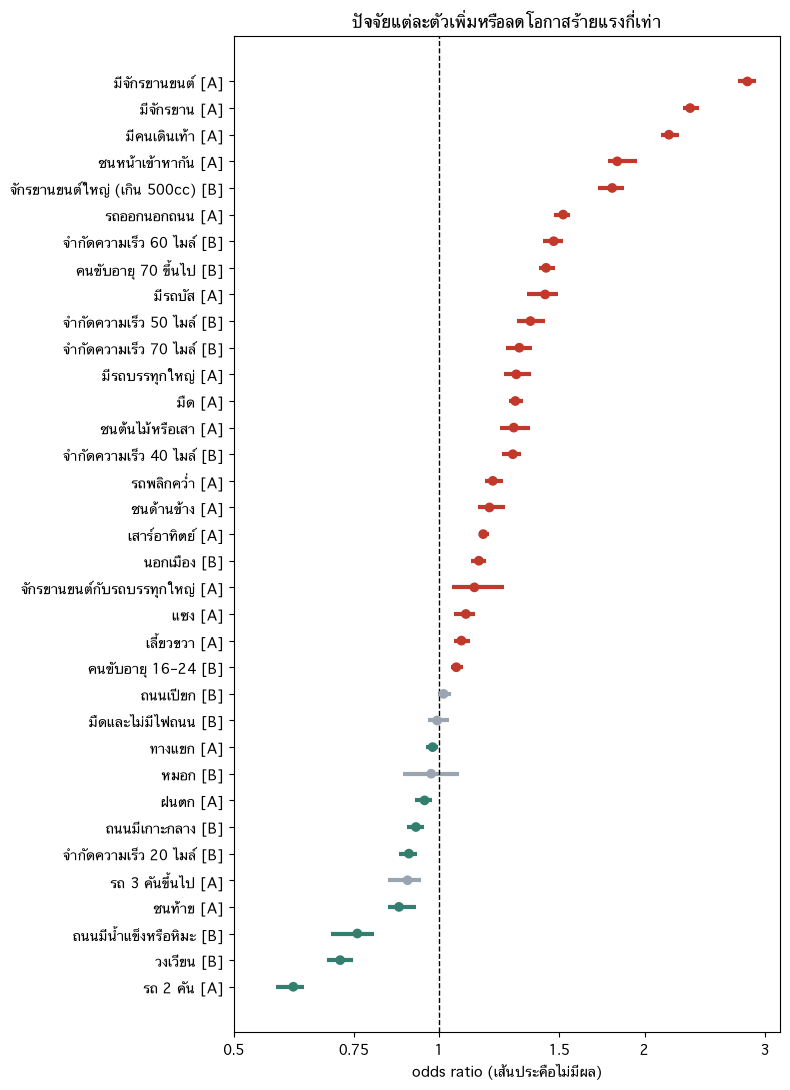

In [38]:
chart = factor_table.iloc[::-1]
colors = []
for result in chart["ผล"]:
    if result == "เพิ่ม":
        colors.append("#c0392b")
    elif result == "ลด":
        colors.append("#327f70")
    else:
        colors.append("#9aa5b1")

labels = []
for name in chart.index:
    labels.append(name + " [" + chart.loc[name, "ชุด"] + "]")

fig, ax = plt.subplots(figsize=(8, 11))
ax.hlines(labels, chart["ต่ำสุด"], chart["สูงสุด"], color=colors, linewidth=3)
ax.scatter(chart["odds ratio"], labels, color=colors, zorder=3)
ax.axvline(1, color="black", linestyle="--", linewidth=1)
ax.set_xscale("log")
# ปิดขีดย่อยของแกน log เพราะตัวเลขของขีดย่อยใช้ฟอนต์ที่ไม่มีเครื่องหมายลบ
ax.minorticks_off()
ax.set_xticks([0.5, 0.75, 1, 1.5, 2, 3])
ax.set_xticklabels(["0.5", "0.75", "1", "1.5", "2", "3"])
ax.set(xlabel="odds ratio (เส้นประคือไม่มีผล)", title="ปัจจัยแต่ละตัวเพิ่มหรือลดโอกาสร้ายแรงกี่เท่า")
plt.tight_layout()
plt.show()

**อ่านกราฟ:** จุดคือ odds ratio เส้นคือช่วงความไม่แน่นอน สีแดงคือเพิ่ม สีเขียวคือลด สีเทาคือไม่ชัด ส่วน [A] และ [B] คือชุดของปัจจัย ช่วงความไม่แน่นอนแคบกว่าเล่มไทยมาก เพราะข้อมูลมากกว่าและปัจจัยแต่ละตัวพบบ่อย

**ปัจจัยที่เพิ่มโอกาสร้ายแรง (23 ตัว)** อันดับต้นคือ
- **ผู้ใช้ถนนที่ไม่มีตัวรถห่อหุ้ม:** มีจักรยานยนต์ 2.8 เท่า มีจักรยาน 2.3 เท่า และมีคนเดินเท้า 2.2 เท่า ถ้าเป็นจักรยานยนต์เกิน 500cc เพิ่มอีก 1.8 เท่า
- **ชนหน้าเข้าหากัน** 1.8 เท่า และ **รถออกนอกถนน** 1.5 เท่า
- **ความเร็วจำกัด:** เทียบกับถนน 30 ไมล์ ถนน 40 ไมล์ 1.3 เท่า ถนน 50 ไมล์ 1.4 เท่า ถนน 60 ไมล์ 1.5 เท่า และถนน 70 ไมล์ 1.3 เท่า เมื่อคุมเรื่องเกาะกลางและแบบของการชนแล้ว ถนน 70 ไมล์ก็อันตรายกว่าถนน 30 ไมล์ ต่างจากตัวเลขดิบในข้อ 4.1
- **คนขับอายุ 70 ขึ้นไป** 1.4 เท่า ส่วนคนขับอายุ 16–24 เพิ่มเพียง 1.06 เท่า
- **มืด** 1.3 เท่า **เสาร์อาทิตย์** 1.16 เท่า และ **นอกเมือง** 1.14 เท่า

**ปัจจัยที่มากับเหตุร้ายแรงน้อยลง (8 ตัว)**
- **รถ 2 คัน** (0.61) เทียบกับเหตุรถคันเดียว ทิศทางตรงข้ามกับเล่มไทย (2.1 เท่า) คำอธิบายที่เป็นไปได้คือข้อมูลไทยมีเหตุรถคันเดียวที่ไม่มีใครบาดเจ็บปนอยู่มาก
- **วงเวียน** (0.72) **ถนนมีน้ำแข็งหรือหิมะ** (0.76) **ถนนมีเกาะกลาง** (0.92) และ **ฝนตก** (0.95): เป็นสภาพที่รถวิ่งช้าลงหรือไม่มีรถสวน ผลเรื่องฝนตรงกับเล่มไทย
- **ชนท้าย** (0.87) **ถนน 20 ไมล์** (0.90) และ **ทางแยก** (0.98 ผลน้อยมาก)

**ปัจจัยที่ยังไม่ชัด (4 ตัว)**
- **มืดและไม่มีไฟถนน** (0.99): ในข้อ 4.3 ถนนมืดที่ไม่มีไฟดูร้ายแรงกว่ามาก แต่เมื่อคุมความเร็วจำกัดและนอกเมืองแล้ว ไฟถนนไม่ได้เพิ่มผลจากความมืดทั่วไป ตัวเลขดิบสูงเพราะถนนที่ไม่มีไฟส่วนใหญ่เป็นถนนนอกเมืองความเร็วสูง
- **ถนนเปียก** (1.02) และ **หมอก** (0.97): ช่วงคร่อม 1
- **รถ 3 คันขึ้นไป** (0.90): สองช่วงปีได้ 1.00 กับ 0.81

**ข้อควรระวัง:** ชนด้านข้าง (1.05 กับ 1.34) และชนท้าย (0.78 กับ 0.98) ได้ค่าสองช่วงปีต่างกันพอสมควร ทิศทางยังเหมือนเดิม แต่ขนาดของผลยังเชื่อไม่ได้เต็มที่ เพราะสองปัจจัยนี้อนุมานจากจุดที่รถถูกชน ไม่ได้บันทึกตรง ๆ

### 10.4 ยิ่งมีปัจจัยเสี่ยงพร้อมกันหลายตัว ยิ่งร้ายแรง
นับว่าแต่ละเหตุมีปัจจัยกลุ่ม "เพิ่ม" กี่ตัว แล้วดูสัดส่วนร้ายแรงจริงของแต่ละกลุ่ม

ปัจจัยกลุ่มเพิ่มที่นับ: 21 ตัว
                                       จำนวนเหตุ  สัดส่วนร้ายแรง
จำนวนปัจจัยเสี่ยง (5 คือ 5 ตัวขึ้นไป)                           
0                                           9288           0.093
1                                          45552           0.189
2                                          71046           0.232
3                                          70855           0.264
4                                          54141           0.313
5                                          58167           0.399


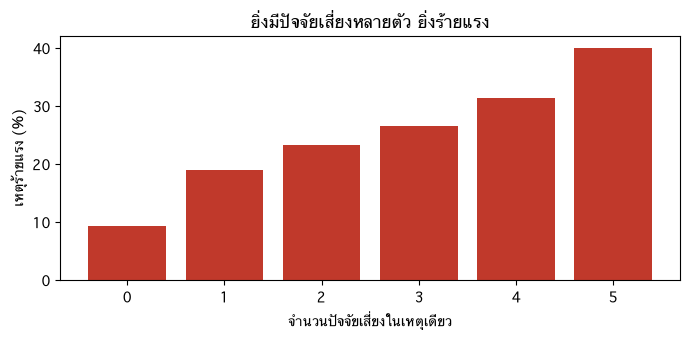

In [39]:
# ไม่นับปัจจัยที่ซ้อนกับปัจจัยอื่น เพราะจะนับซ้ำ
nested_factors = ["จักรยานยนต์กับรถบรรทุกใหญ่", "จักรยานยนต์ใหญ่ (เกิน 500cc)", "มืดและไม่มีไฟถนน"]

risk_factors = []
for factor in factor_table.index[factor_table["ผล"].eq("เพิ่ม")]:
    if factor not in nested_factors:
        risk_factors.append(factor)
print("ปัจจัยกลุ่มเพิ่มที่นับ:", len(risk_factors), "ตัว")

risk_count = factors[risk_factors].sum(axis=1).clip(upper=5)
by_risk_count = clean.groupby(risk_count)["severe"].agg(["size", "mean"])
by_risk_count.columns = ["จำนวนเหตุ", "สัดส่วนร้ายแรง"]
by_risk_count.index.name = "จำนวนปัจจัยเสี่ยง (5 คือ 5 ตัวขึ้นไป)"
print(by_risk_count.round(3))

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(by_risk_count.index, by_risk_count["สัดส่วนร้ายแรง"] * 100, color="#c0392b")
ax.set(xlabel="จำนวนปัจจัยเสี่ยงในเหตุเดียว", ylabel="เหตุร้ายแรง (%)", title="ยิ่งมีปัจจัยเสี่ยงหลายตัว ยิ่งร้ายแรง")
plt.tight_layout()
plt.show()

**อ่านกราฟ:** เหตุที่ไม่มีปัจจัยเสี่ยงเลยร้ายแรง 9.3% เหตุที่มี 2 ตัวร้ายแรง 23.2% มี 4 ตัวร้ายแรง 31.3% และมี 5 ตัวขึ้นไปร้ายแรง 39.9%

เหตุร้ายแรงจึงเกิดจากหลายปัจจัยซ้อนกันเหมือนในไทย แต่ความต่างระหว่างกลุ่มน้อยกว่าไทย (7.8% ถึง 61.8%) และเหตุที่ไม่มีปัจจัยเสี่ยงเลยมีเพียง 3% ของเหตุทั้งหมด ปัจจัยเสี่ยงจึงพบได้ทั้งในเหตุร้ายแรงและไม่ร้ายแรง

### 10.5 ตรวจซ้ำด้วยโมเดลอีกแบบ
ใช้ **permutation importance** กับ Gradient Boosting บน Test คือสลับค่าของคอลัมน์หนึ่งแบบสุ่ม แล้วดูว่า PR-AUC ลดลงเท่าไร ถ้าลดมากแปลว่าโมเดลพึ่งคอลัมน์นั้นมาก

In [40]:
importance = permutation_importance(boosting_model, test_x, test_y, scoring="average_precision",
                                    n_repeats=3, random_state=42)
importance_table = pd.Series(importance.importances_mean, index=model_columns)
importance_table = importance_table.sort_values(ascending=False)
importance_table.head(12).round(3)

มีจักรยานยนต์            0.070
มีคนเดินเท้า             0.035
มีจักรยาน                0.030
police_force             0.024
รถ 2 คัน                 0.024
รถออกนอกถนน              0.016
จำกัดความเร็ว 60 ไมล์    0.011
ชนหน้าเข้าหากัน          0.010
นอกเมือง                 0.008
ชนท้าย                   0.006
มืด                      0.006
จำกัดความเร็ว 70 ไมล์    0.006
dtype: float64

**อ่านตาราง:** Gradient Boosting พึ่ง `มีจักรยานยนต์` มากที่สุด (PR-AUC ลด 0.070) ตามด้วยคนเดินเท้า (0.035) จักรยาน (0.030) เขตตำรวจ (0.024) และรถ 2 คัน (0.024) ตรงกับปัจจัยอันดับต้นของ Logistic Regression โมเดลสองแบบจึงเห็นตรงกัน

ปัจจัยชุด B ที่สำคัญที่สุดคือถนน 60 ไมล์ (0.011) นอกเมือง (0.008) และถนน 70 ไมล์ (0.006) ข้อมูลที่ไทยไม่มีจึงช่วยได้ แต่น้อยกว่าคำถามว่า "ใครอยู่ในเหตุ"

## 11. คำตอบส่วนที่ 2: เหตุครั้งนี้ร้ายแรงเพราะอะไร
ใช้วิธีเดียวกับเล่มไทย คือถามโมเดลว่า "ถ้าเหตุนี้ไม่มีปัจจัยนี้ โอกาสร้ายแรงจะเหลือเท่าไร" ส่วนต่างคือ **แรงผลัก** ของปัจจัยนั้น หน่วยเป็นจุดเปอร์เซ็นต์

"ไม่มีปัจจัยนี้" หมายถึงเปลี่ยนเป็นกรณีอ้างอิง เช่น เอา "จำกัดความเร็ว 60 ไมล์" ออกคือเปลี่ยนเป็นถนน 30 ไมล์ และถ้าเอา "มีจักรยานยนต์" ออก จักรยานยนต์ใหญ่ก็หายไปด้วย

ใช้ `test_model` ที่ฝึกด้วยปี 2021–2024 กับเหตุใน Test

In [41]:
combined_factor = "จักรยานยนต์กับรถบรรทุกใหญ่"

# ปัจจัยที่เอาออกทีละตัวได้ คือทุกตัวยกเว้นปัจจัยรวม
single_factors = []
for factor in factor_names:
    if factor != combined_factor:
        single_factors.append(factor)


def remove_factor(rows, factor):
    changed = rows.copy()
    changed[factor] = 0
    # ปัจจัยที่ขึ้นกับปัจจัยอื่น ต้องคำนวณใหม่
    if factor == "มีจักรยานยนต์":
        changed["จักรยานยนต์ใหญ่ (เกิน 500cc)"] = 0
    if factor == "มืด":
        changed["มืดและไม่มีไฟถนน"] = 0
    changed[combined_factor] = changed["มีจักรยานยนต์"] * changed["มีรถบรรทุกใหญ่"]
    return changed


def predict_without(model, rows, factor):
    return model.predict_proba(remove_factor(rows, factor))[:, 1]


def explain_accident(model, one_row):
    probability = model.predict_proba(one_row)[0, 1]
    names = []
    pushes = []
    for factor in single_factors:
        if one_row[factor].iloc[0] == 1:
            probability_without = predict_without(model, one_row, factor)[0]
            names.append(factor)
            pushes.append((probability - probability_without) * 100)
    explanation = pd.DataFrame({"ปัจจัย": names, "แรงผลัก (จุด %)": pushes})
    explanation = explanation.sort_values("แรงผลัก (จุด %)", ascending=False).reset_index(drop=True)
    return probability, explanation

In [42]:
def show_example(title, row_index):
    one_row = test_x.loc[[row_index]]
    probability, explanation = explain_accident(test_model, one_row)
    print(title)
    print("ร้ายแรงจริงไหม:", int(test_y.loc[row_index]), "| โมเดลให้โอกาสร้ายแรง:", round(probability * 100, 1), "%")
    print(explanation.round(1).to_string(index=False))
    print()


# ตัวอย่างที่ 1: เหตุร้ายแรงที่จักรยานยนต์ออกนอกถนนบนถนน 60 ไมล์
rows_1 = test_x.loc[test_y.eq(1) & test_x["มีจักรยานยนต์"].eq(1) & test_x["จำกัดความเร็ว 60 ไมล์"].eq(1)
                    & test_x["รถออกนอกถนน"].eq(1)]
show_example("ตัวอย่างที่ 1", rows_1.index[0])

# ตัวอย่างที่ 2: เหตุร้ายแรงที่มีคนเดินเท้า ตอนมืด
rows_2 = test_x.loc[test_y.eq(1) & test_x["มีคนเดินเท้า"].eq(1) & test_x["มืด"].eq(1)]
show_example("ตัวอย่างที่ 2", rows_2.index[0])

# ตัวอย่างที่ 3: เหตุร้ายแรงที่ไม่มีปัจจัยกลุ่มเพิ่มเลย
rows_3 = test_x.loc[test_y.eq(1) & test_x[risk_factors].sum(axis=1).eq(0)]
show_example("ตัวอย่างที่ 3", rows_3.index[0])

ตัวอย่างที่ 1
ร้ายแรงจริงไหม: 1 | โมเดลให้โอกาสร้ายแรง: 78.8 %
                      ปัจจัย  แรงผลัก (จุด %)
               มีจักรยานยนต์             37.4
จักรยานยนต์ใหญ่ (เกิน 500cc)             10.4
                 รถออกนอกถนน              8.3
       จำกัดความเร็ว 60 ไมล์              7.3
         คนขับอายุ 70 ขึ้นไป              6.7
                เสาร์อาทิตย์              2.9
                    นอกเมือง              2.3
                    ถนนเปียก              0.2
                      ทางแยก             -0.5
                        หมอก             -0.8

ตัวอย่างที่ 2
ร้ายแรงจริงไหม: 1 | โมเดลให้โอกาสร้ายแรง: 46.6 %
      ปัจจัย  แรงผลัก (จุด %)
มีคนเดินเท้า             18.7
 รถออกนอกถนน             10.6
         มืด              6.7
เสาร์อาทิตย์              4.1
      ทางแยก             -0.7

ตัวอย่างที่ 3
ร้ายแรงจริงไหม: 1 | โมเดลให้โอกาสร้ายแรง: 12.0 %
  ปัจจัย  แรงผลัก (จุด %)
  ทางแยก             -0.3
    ฝนตก             -0.5
รถ 2 คัน             -5.1



**อ่านผล:**
- **ตัวอย่างที่ 1:** โมเดลให้ 78.8% ปัจจัยหลักคือมีจักรยานยนต์ (+37.4 จุด) รองลงมาคือเป็นจักรยานยนต์เกิน 500cc (+10.4) รถออกนอกถนน (+8.3) ถนน 60 ไมล์ (+7.3) และคนขับอายุ 70 ขึ้นไป (+6.7) ปัจจัยชุด B ช่วยอธิบายเหตุนี้ได้ละเอียดขึ้น
- **ตัวอย่างที่ 2:** โมเดลให้ 46.6% เพราะมีคนเดินเท้า (+18.7) รถออกนอกถนน (+10.6) และมืด (+6.7)
- **ตัวอย่างที่ 3:** เหตุนี้ร้ายแรงจริง แต่โมเดลให้เพียง 12.0% เพราะเป็นรถ 2 คันชนกันที่ทางแยกตอนฝนตก ปัจจัยทุกตัวดึงโอกาสลง โมเดลจึงอธิบายเหตุนี้ไม่ได้ เหมือนตัวอย่างที่ 3 ของเล่มไทย

แรงผลักรวมกันไม่เท่ากับโอกาสร้ายแรงพอดี เพราะปัจจัยมีผลแบบคูณกัน ตัวเลขนี้ใช้เรียงว่าปัจจัยไหนสำคัญกว่าในเหตุนั้น

### 11.1 เหตุร้ายแรงทั้งหมดใน Test ร้ายแรงเพราะปัจจัยไหนมากที่สุด
หา **ปัจจัยหลัก** ของแต่ละเหตุ คือปัจจัยที่มีแรงผลักมากที่สุด ถ้าแรงผลักมากที่สุดยังไม่ถึง 2 จุด นับว่า "ไม่มีปัจจัยเด่น" (เกณฑ์เดียวกับเล่มไทย)

In [43]:
pushes = pd.DataFrame(index=test_x.index)
for factor in single_factors:
    probability_without = predict_without(test_model, test_x, factor)
    push = test_prob - probability_without
    # เหตุที่ไม่มีปัจจัยนี้ แรงผลักเป็น 0
    push[test_x[factor].values == 0] = 0
    pushes[factor] = push

main_factor = pushes.idxmax(axis=1)
main_push = pushes.max(axis=1)
main_factor.loc[main_push < 0.02] = "ไม่มีปัจจัยเด่น"

severe_main = main_factor.loc[test_y.eq(1)].value_counts(normalize=True) * 100
other_main = main_factor.loc[test_y.eq(0)].value_counts(normalize=True) * 100

main_table = pd.DataFrame({
    "เหตุร้ายแรง (%)": severe_main,
    "เหตุไม่ร้ายแรง (%)": other_main,
}).fillna(0)
main_table = main_table.sort_values("เหตุร้ายแรง (%)", ascending=False)
print("เหตุร้ายแรงใน Test:", int(test_y.sum()), "เหตุ")
main_table.head(10).round(1)

เหตุร้ายแรงใน Test: 23720 เหตุ


,เหตุร้ายแรง (%),เหตุไม่ร้ายแรง (%)
มีจักรยานยนต์,22.9,13.4
มีคนเดินเท้า,21.0,16.2
มีจักรยาน,16.7,15.5
รถออกนอกถนน,12.4,11.2
ชนหน้าเข้าหากัน,9.4,7.8
ไม่มีปัจจัยเด่น,4.0,12.2
มืด,2.9,6.0
จำกัดความเร็ว 60 ไมล์,2.5,3.5
คนขับอายุ 70 ขึ้นไป,2.4,3.2
จำกัดความเร็ว 70 ไมล์,1.7,3.2


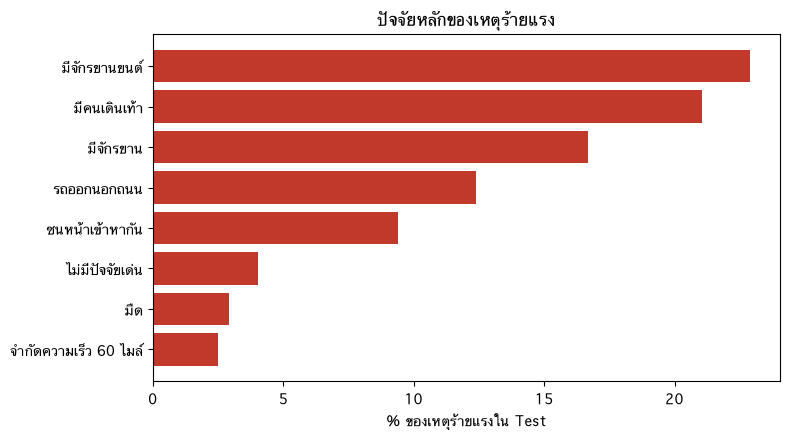

In [44]:
top_main = main_table.head(8).iloc[::-1]

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(top_main.index, top_main["เหตุร้ายแรง (%)"], color="#c0392b")
ax.set(xlabel="% ของเหตุร้ายแรงใน Test", title="ปัจจัยหลักของเหตุร้ายแรง")
plt.tight_layout()
plt.show()

**อ่านกราฟ:** ในเหตุร้ายแรง 23,720 เหตุ
- **22.9%** มีจักรยานยนต์เป็นปัจจัยหลัก ขณะที่เหตุไม่ร้ายแรงมี 13.4% น้อยกว่าไทย (53.5%) มาก เพราะอังกฤษมีจักรยานยนต์ในเหตุน้อยกว่า
- **21.0%** มีคนเดินเท้าเป็นปัจจัยหลัก และ **16.7%** มีจักรยาน แต่เหตุไม่ร้ายแรงก็มีสัดส่วนใกล้กัน (16.2% และ 15.5%)
- **4.0%** ไม่มีปัจจัยเด่น น้อยกว่าเล่มไทย (12.0%) เพราะมีปัจจัยให้ใช้อธิบายมากกว่า

ตารางนี้อธิบายว่าทำไมคะแนนทำนายไม่สูงทั้งที่ปัจจัยชัด ปัจจัยหลักของเหตุร้ายแรงพบในเหตุไม่ร้ายแรงด้วยในสัดส่วนใกล้กัน โมเดลจึงบอกได้ว่าเหตุไหน "เสี่ยง" แต่บอกไม่ได้แน่ชัดว่าเหตุไหน "จะร้ายแรงจริง"

## 12. บันทึกโมเดล
บันทึก `final_model` ที่ฝึกด้วยข้อมูลทุกปี ตารางปัจจัยถูกบันทึกไปแล้วในหัวข้อ 10.3

In [45]:
model_path = model_dir / "factor_model.joblib"
joblib.dump(final_model, model_path)
print("บันทึกแล้ว:", model_path.relative_to(project_dir))

บันทึกแล้ว: data/explore_idea/uk_severity_factors/model/factor_model.joblib


## 13. สรุป

### สามอย่างที่ต้องมี

| หัวข้อ | คำตอบ |
|---|---|
| **Input feature** | ปัจจัยแบบมีหรือไม่มี 35 ตัว (int 0/1) แบ่งเป็นชุด A 20 ตัวแบบที่ข้อมูลไทยมี และชุด B 15 ตัวที่ไทยไม่มี กับเขตตำรวจ (category) ที่ใช้คุมความต่างของพื้นที่ |
| **Model type** | Logistic Regression เพราะให้ตัวเลขหนึ่งตัวต่อหนึ่งปัจจัย |
| **Evaluation metric** | ชั้นที่ 1: PR-AUC, PR-AUC ÷ เดาสุ่ม, ROC-AUC, Brier score และ Calibration บน Test (ปี 2025) ชั้นที่ 2: odds ratio คงที่ข้ามช่วงปีไหม และช่วงความไม่แน่นอนจาก bootstrap 100 รอบ |

### คำถามที่ 1: ปัจจัยอะไรทำให้เหตุร้ายแรง
- **สรุปทิศทางได้ 31 จาก 35 ปัจจัย:** เพิ่ม 23 ตัว ลด 8 ตัว และไม่ชัด 4 ตัว ช่วงความไม่แน่นอนแคบเพราะข้อมูลมาก
- **ปัจจัยที่แรงที่สุด:** มีจักรยานยนต์ (odds 2.8 เท่า) มีจักรยาน (2.3) มีคนเดินเท้า (2.2) ชนหน้าเข้าหากัน (1.8) จักรยานยนต์เกิน 500cc (เพิ่มอีก 1.8) รถออกนอกถนน (1.5) ถนน 60 ไมล์ (1.5) และคนขับอายุ 70 ขึ้นไป (1.4)
- **ตรงกับเล่มไทย:** ผู้ใช้ถนนที่ไม่มีตัวรถห่อหุ้มเป็นปัจจัยอันดับต้น ชนหน้าเข้าหากันและความมืดเพิ่มความร้ายแรง ฝนตกมากับเหตุที่ร้ายแรงน้อยลง
- **ตัวเลขดิบหลอกตา 2 เรื่อง:** ถนน 70 ไมล์ดูปลอดภัยเพราะมีเกาะกลางและชนท้ายเป็นส่วนใหญ่ เมื่อคุมแล้วอันตรายกว่าถนน 30 ไมล์ 1.3 เท่า ส่วนถนนมืดที่ไม่มีไฟดูอันตราย แต่เมื่อคุมความเร็วจำกัดแล้ว ไฟถนนไม่ได้เพิ่มผลจากความมืดทั่วไป
- **เหตุร้ายแรงมักมีหลายปัจจัยซ้อนกัน:** ไม่มีปัจจัยเสี่ยงเลยร้ายแรง 9.3% มี 5 ตัวขึ้นไปร้ายแรง 39.9%

### คำถามที่ 2: ถ้ามีข้อมูลที่ไทยไม่มี โมเดลดีขึ้นไหม
- **ดีขึ้นเล็กน้อย:** PR-AUC เพิ่มจาก 0.404 เป็น 0.434 และ ROC-AUC เพิ่มจาก 0.657 เป็น 0.675
- **ข้อมูลไทยไม่ได้แย่กว่า:** เมื่อเทียบแบบยุติธรรม (เฉพาะเหตุที่มีผู้บาดเจ็บ) ข้อมูลไทยได้ ROC-AUC 0.752 สูงกว่าข้อมูลอังกฤษ
- **คะแนนทำนายรายเหตุจะไม่สูงมากไม่ว่าใช้ข้อมูลตำรวจชุดไหน:** สิ่งที่ตัดสินว่าผู้บาดเจ็บจะสาหัสหรือไม่ เช่น ความเร็วตอนชน หมวกนิรภัย เข็มขัด และร่างกายของผู้บาดเจ็บ ไม่มีในข้อมูลตำรวจของทั้งสองประเทศ

### ข้อจำกัด
- **เป็นความสัมพันธ์ ไม่ใช่การพิสูจน์สาเหตุ:** โมเดลคุมได้เฉพาะสิ่งที่มีในข้อมูล
- **ใช้เฉพาะเหตุที่บันทึกด้วยระบบใหม่:** ตัดเหตุออก 40% และเขตตำรวจที่ยังไม่เปลี่ยนระบบไม่อยู่ในผล
- **ลักษณะการชนเป็นค่าอนุมาน:** สร้างจากจุดที่รถถูกชน ชนด้านข้างและชนท้ายจึงได้ค่าสองช่วงปีต่างกันพอสมควร
- **ไม่มีปัจจัยทางโค้ง:** รหัสชุดใหม่ของปี 2024 รวมการขับบนโค้งเข้ากับการขับตรงไป
- **บริบทต่างจากไทย:** อังกฤษมีจักรยานยนต์ใน 13.4% ของเหตุ ส่วนไทยมี 21.4% และจักรยานยนต์ในอังกฤษเครื่องใหญ่กว่า ขนาดของผลจึงนำมาใช้กับไทยตรง ๆ ไม่ได้ แต่ทิศทางของปัจจัยใช้อ้างอิงได้